In [1]:
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
from collections import Counter
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
import sklearn.linear_model
from matplotlib import pyplot
from numpy import where
from sklearn import metrics
from sklearn import preprocessing
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
import sklearn.svm
import sklearn.gaussian_process
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold
from sklearn.model_selection import learning_curve
from sklearn.model_selection import train_test_split
from sklearn.model_selection import validation_curve
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [2]:
### LIB TO OPEN EXCEL FILE
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path
import joblib

In [3]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


## Importing Original Data after removing unwanted columns

In [4]:
root_dir='/content/gdrive/MyDrive/ResearchProject/'
#data_dir = '/content/gdrive/MyDrive/ResearchProject/data/new_data/'
data_dir="/content/gdrive/MyDrive/ResearchProject/data/labeled_normal_data/new_TLSI_input/all_pids_q=0.2.npy"
output_dir = root_dir + "classification_results_2023/"
#original_data= pd.read_csv(data_dir+"/SB-023_original.csv")


In [5]:
data_ndarr = np.load(data_dir, allow_pickle=True)
print("data_ndarr type :", type(data_ndarr))

datadict = data_ndarr.item()
print("datadict type :", type(datadict))

data_ndarr type : <class 'numpy.ndarray'>
datadict type : <class 'dict'>


In [6]:
p_ids = datadict.keys()
smaple_size_dict={}
print("patients: n =", len(p_ids), end='\n\n')

for p_id in p_ids:
    df = datadict[p_id]
    # drop column from input data file
    #df.drop(['id','date','am_pef_org','BMI','sex'], axis=1, inplace=True) #ALL DROPS SHOULD OCCUR HERE
    df.drop(['id','date','am_pef_org','BMI','sex', 'age'], axis=1, inplace=True) #,'id','date','am_pef_org','BMI',  'sex', 'age'
    df = np.asarray(df).astype(np.float32)
    print(p_id, "shape:", df.shape)#, end="\t\t")
    smaple_size_dict[p_id]=df.shape[0]

datadict[p_id].head(4)

patients: n = 26

SB-001 shape: (188, 28)
SB-003 shape: (180, 28)
SB-008 shape: (178, 28)
SB-011 shape: (210, 28)
SB-012 shape: (194, 28)
SB-022 shape: (204, 28)
SB-023 shape: (194, 28)
SB-025 shape: (117, 28)
SB-028 shape: (92, 28)
SB-033 shape: (53, 28)
SB-037 shape: (210, 28)
SB-043 shape: (191, 28)
SB-056 shape: (191, 28)
SB-059 shape: (203, 28)
SB-060 shape: (88, 28)
SB-070 shape: (202, 28)
SB-071 shape: (124, 28)
SB-073 shape: (161, 28)
SB-078 shape: (153, 28)
SB-079 shape: (142, 28)
SB-080 shape: (181, 28)
SB-081 shape: (34, 28)
SB-082 shape: (137, 28)
SB-083 shape: (206, 28)
SB-089 shape: (49, 28)
SB-112 shape: (180, 28)


,income,road_dist,cooking,y_am_pef,tempin,humidin,pm25in,co2in,tempdiffin,humidiffin,...,windsd,humid,varp,dewpt,airp,seap,solrhr,solramnt,grdt,class
1,0.857,0.0,0.167,0.558,0.216,0.513,0.358,0.678,0.562,0.364,...,0.107,0.668,0.174,0.471,0.822,0.819,0.165,0.003,0.206,0.0
2,0.857,0.0,0.167,0.006,0.299,0.521,0.411,0.700,0.436,0.672,...,0.171,0.388,0.190,0.491,0.676,0.670,0.603,0.165,0.383,0.0
3,0.857,0.0,0.167,0.078,0.420,0.713,0.372,0.918,0.469,0.821,...,0.515,0.359,0.197,0.481,0.519,0.518,0.485,0.104,0.346,1.0
4,0.857,0.0,0.167,0.428,0.438,0.468,0.224,0.762,0.560,0.490,...,0.338,0.527,0.175,0.467,0.596,0.596,0.491,0.141,0.339,0.0


In [7]:
target_grp = ["SB-028", "SB-011", "SB-112", "SB-001", "SB-012", "SB-073", "SB-078", "SB-080", "SB-083", "SB-043", "SB-037", "SB-022", "SB-025", "SB-060", "SB-023", "SB-071", "SB-033", "SB-079", "SB-056", "SB-059", "SB-003", "SB-089", "SB-082", "SB-008", "SB-070"]


## Importing classification py module

In [8]:
import importlib.util
import os
spec = importlib.util.spec_from_file_location('classification', root_dir + 'classification/Base_Model/Classificationv3.py')
module = importlib.util.module_from_spec(spec)

spec.loader.exec_module(module)

In [9]:
predictColumn = "class"
minorityVariable = 0 # must be an integer


## Method for calling classification algo functions for classifying the data and showing the results

In [10]:
#EVALUATION_METRICS = ['Weighted Accuracy', 'Sensitivity/Recall', 'Precision_avg', 'F1_avg', 'Specificity', 'Precision', 'Precision_class1', 'F1', 'F1_class1']
EVALUATION_METRICS = ["Weighted Accuracy", "Sensitivity/Recall", "Specificity", "Precision_class0", "Precision_class1", "Precision_avg", "F1_class0", "F1_class1", "F1_avg", "auc_roc_score", "False_Discovery_Rate", "False_Negative_Rate", "False_Omission_Rate", "False_Positive_Rate", "Jaccard"]


In [11]:
#patient_id="SB-023/"
#file_name="SB-023"
#file_name_synthetic="SB-001_synthetic"

In [12]:
def classification_func(file_name,target, predictCol, minorVar, category_group, cls, output_dir, df_evaluation_results):
    #runtime()

 #   if len(cls)!=2:
  #    print('process one model each time')
   #   return

    print('~~~~~~~~~~~~~~~~~', file_name,'~~~~~~~~~~~~~~~~~~~~~~')
#+ file_name + '/'
    dataset_dir = Path(output_dir +target+'/'+category_group +  "/diagrams/" ) #RESULT_DIR

    # Create Directory for this patient
    if not (dataset_dir.exists() and dataset_dir.is_dir()):
        os.makedirs(dataset_dir)

    print(dataset_dir)

    save_path = output_dir+ target+'/'+category_group +'/diagrams/' + 'sklearn_models_'
    print(save_path)

    CLASS_VAR = predictCol
    MINORITY_VAR = minorVar
## change the data attribute in the Classify method below for eg: original_data or synthetic_data
    dataset = pd.DataFrame()

    dataset=datadict[target].copy()
    bestDT = module.Classify(dataset,target, True, class_var=CLASS_VAR, minority_var=MINORITY_VAR, drawConfusionMatrix=True, classifiers=cls, scale=True, save_path=save_path, after_split=True)

    confusion_matrixes_file = save_path + "confusion_mat_" + category_group + "_"+ file_name
    module.save_confusion_matrix(bestDT[1], confusion_matrixes_file)
    roc_curve_file = save_path + "roc_curve_" + category_group + "_"+ file_name
    module.save_Draw_Roc(bestDT[2], roc_curve_file)
    if len(bestDT[3])!=0:
      featureImportance_path = save_path + "important_mat_" + category_group + "_"+ file_name
      module.save_Draw_FeatureImportanceMatrix(dataset,target,bestDT[3],cls[0], featureImportance_path, True)

    model_path = save_path + "bestModel_" + category_group + "_"+ file_name + ".joblib"
    joblib.dump(bestDT[4], model_path)
    loaded_model = joblib.load(model_path)
    print(loaded_model)

    df_evaluation_results[file_name] = bestDT[0]
    df_evaluation_results.to_csv(output_dir+target+'/'+category_group+"/sklearn_models_balanced_for_train_metrics_"+category_group + ".csv")


In [13]:
%run  '/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py'

In [14]:
%run  '/content/gdrive/MyDrive/ResearchProject/BalancingAlgorithms/Balance.py'

## K-NN

In [19]:
def KNNRunner(category_group):
  for target in tqdm(p_ids):
    if target in ['SB-081','SB-089','SB-033']:
      continue
    df_evaluation_results = pd.DataFrame(index=EVALUATION_METRICS)
    cls = ["K-NN", sklearn.neighbors.KNeighborsClassifier()]
    file_name=target
    classification_func(file_name,target, predictColumn, minorityVariable, category_group, cls, output_dir, df_evaluation_results)

  0%|          | 0/26 [00:00<?, ?it/s]

~~~~~~~~~~~~~~~~~ SB-001 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-001/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-001/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  125  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  125  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  206  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  126  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  204  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.6808367071524966 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 4  5]
 [18 36]]
cm.ravel() [ 4  5 18 36]
----- [0.55555556 0.44444444 0.66666667 0.18181818 0.87804878 0.52993348
 0.25806452 0.75789474 0.50797963 0.55555556 0.55555556 0.12195122
 0.33333333 0

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7871080139372821 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 7  8]
 [15 33]]
cm.ravel() [ 7  8 15 33]
----- [0.57708333 0.46666667 0.6875     0.31818182 0.80487805 0.56152993
 0.37837838 0.74157303 0.55997571 0.57708333 0.53333333 0.19512195
 0.3125     0.68181818 0.23333333] [[ 7  8]
 [15 33]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 7  6]
 [15 34]]
cm.ravel() [ 7  6 15 34]
----- [0.61616954 0.53846154 0.69387755 0.31818182 0.85       0.58409091
 0.4        0.76404494 0.58202247 0.61616954 0.46153846 0.15
 0.30612245 0.68181818 0.25      ] [[ 7  6]
 [15 34]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


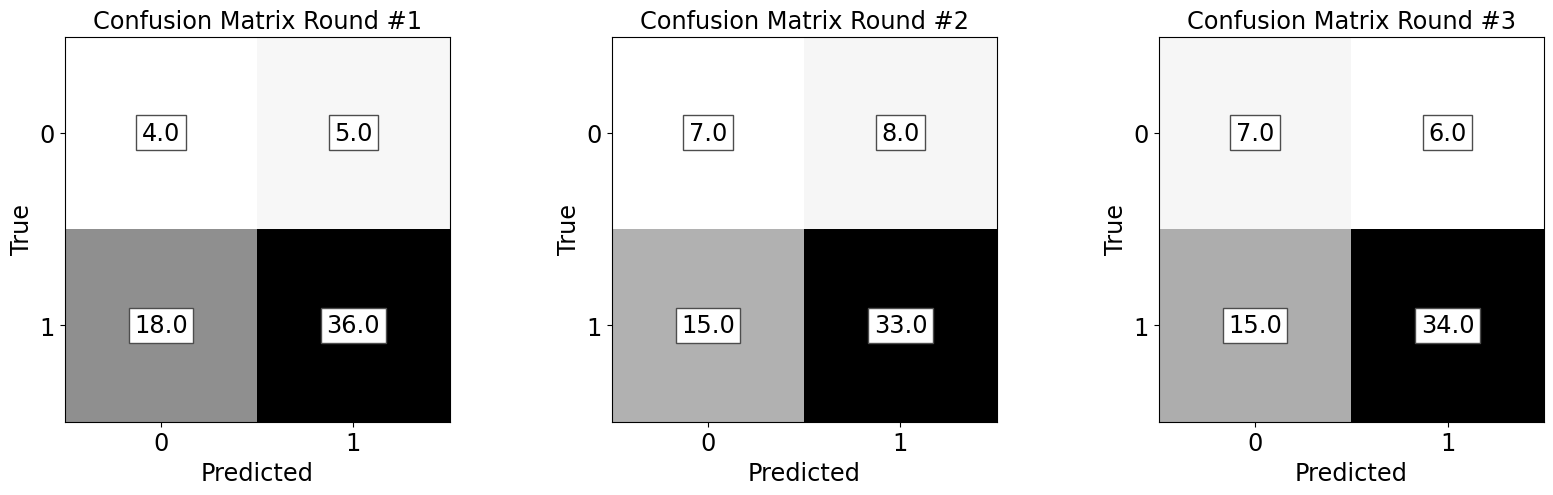

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


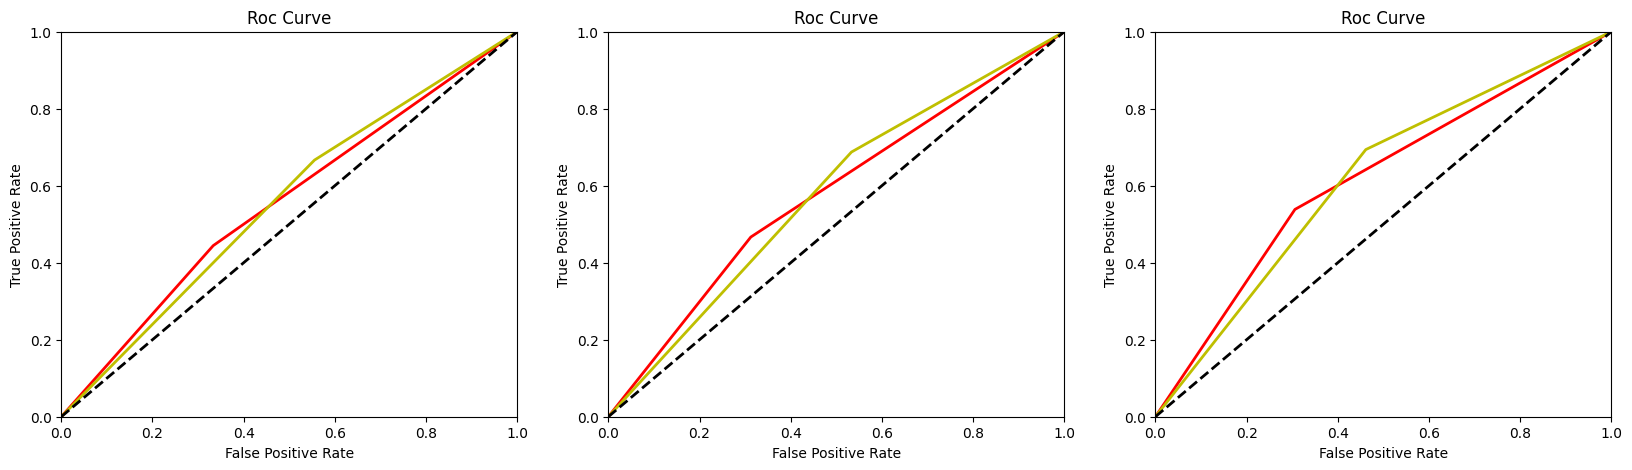

  4%|▍         | 1/26 [00:05<02:07,  5.09s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-003 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-003/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-003/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  188  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  180  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  180  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.6071123755334282 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 5 12]
 [14 29]]
cm.ravel() [ 5 12 14 29]
----- [0.48426813 0.29411765 0.6744186  0.26315789 0.70731707 0.4

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.6444444444444445 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 5  8]
 [27 20]]
cm.ravel() [ 5  8 27 20]
----- [0.40507365 0.38461538 0.42553191 0.15625    0.71428571 0.43526786
 0.22222222 0.53333333 0.37777778 0.40507365 0.61538462 0.28571429
 0.57446809 0.84375    0.125     ] [[ 5  8]
 [27 20]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 3 10]
 [25 22]]
cm.ravel() [ 3 10 25 22]
----- [0.34942717 0.23076923 0.46808511 0.10714286 0.6875     0.39732143
 0.14634146 0.55696203 0.35165174 0.34942717 0.76923077 0.3125
 0.53191489 0.89285714 0.07894737] [[ 3 10]
 [25 22]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


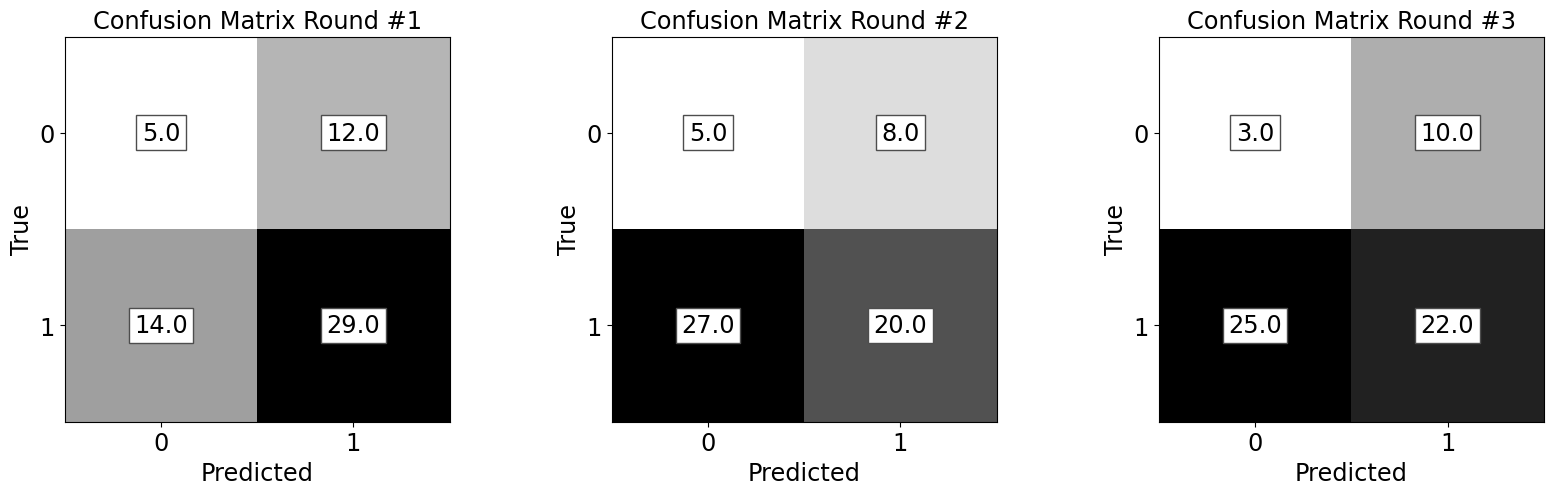

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


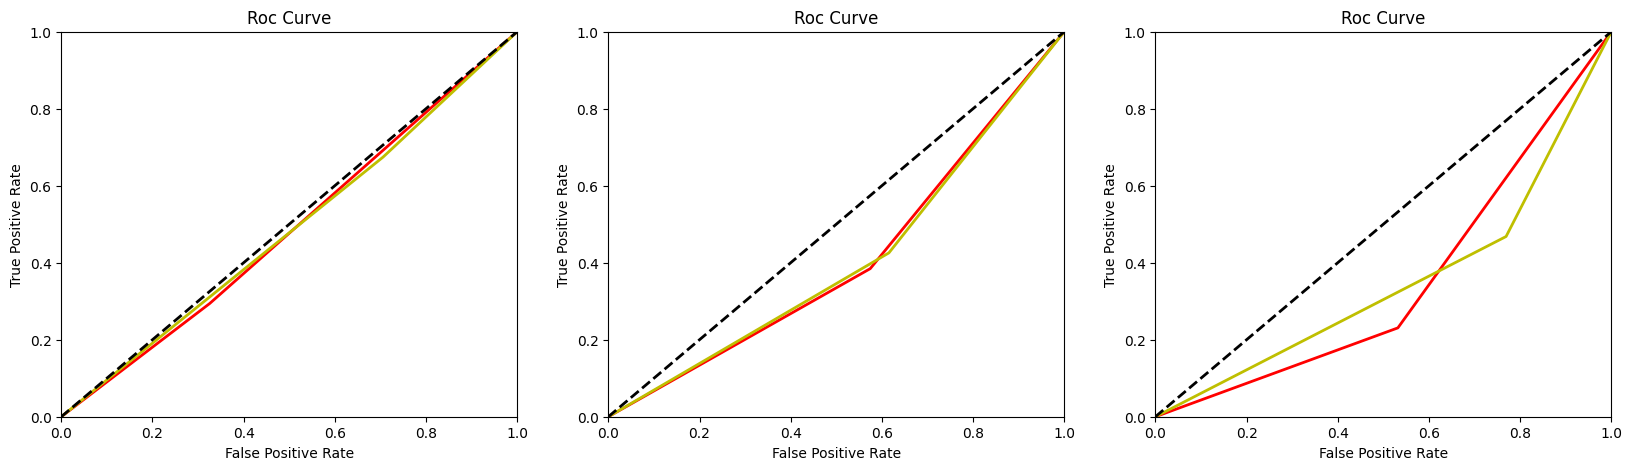

  8%|▊         | 2/26 [00:08<01:37,  4.06s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-008 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-008/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-008/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  118  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  172  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  119  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  182  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  119  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  186  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7164705882352941 KNeighborsClassifier(metric='manhattan', n_neighbors=3, weights='distance')
cm [[ 7  4]
 [15 34]]
cm.ravel() [ 7  4 15 34]
----- [0.66512059 0.63636364 0.69387755 0.318

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7539039039039038 KNeighborsClassifier(metric='manhattan', n_neighbors=3, weights='distance')
cm [[12  3]
 [16 28]]
cm.ravel() [12  3 16 28]
----- [0.71818182 0.8        0.63636364 0.42857143 0.90322581 0.66589862
 0.55813953 0.74666667 0.6524031  0.71818182 0.2        0.09677419
 0.36363636 0.57142857 0.38709677] [[12  3]
 [16 28]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7584637268847796 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[11  6]
 [17 25]]
cm.ravel() [11  6 17 25]
----- [0.62114846 0.64705882 0.5952381  0.39285714 0.80645161 0.59965438
 0.48888889 0.68493151 0.5869102  0.62114846 0.35294118 0.19354839
 0.4047619  0.60714286 0.32352941] [[11  6]
 [17 25]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


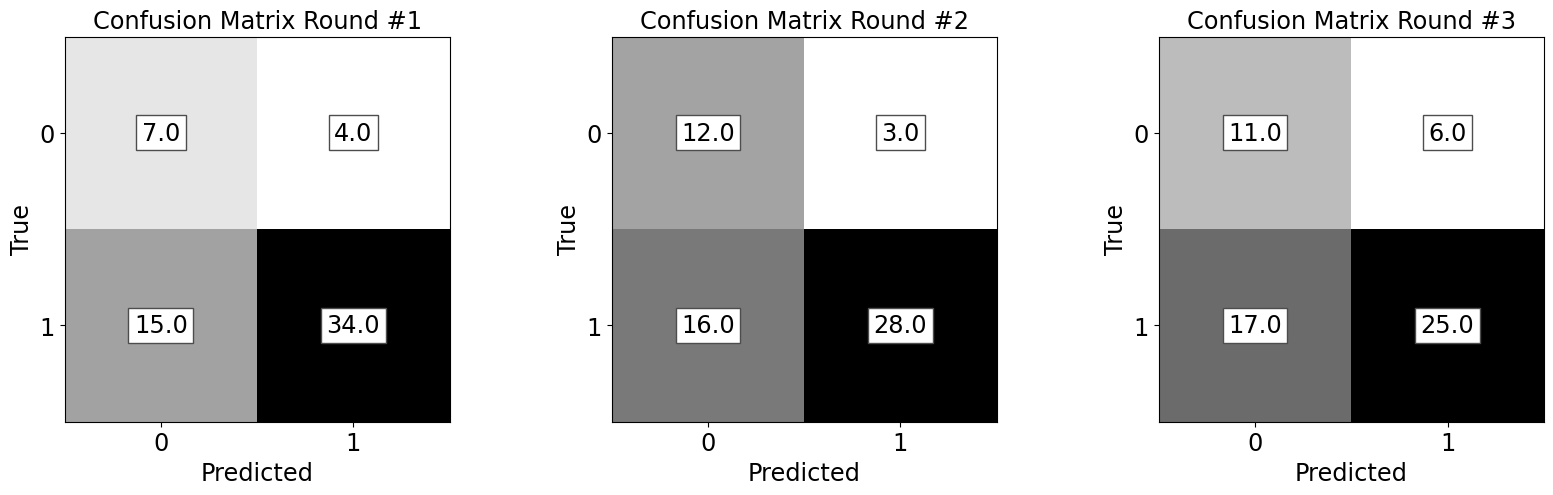

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


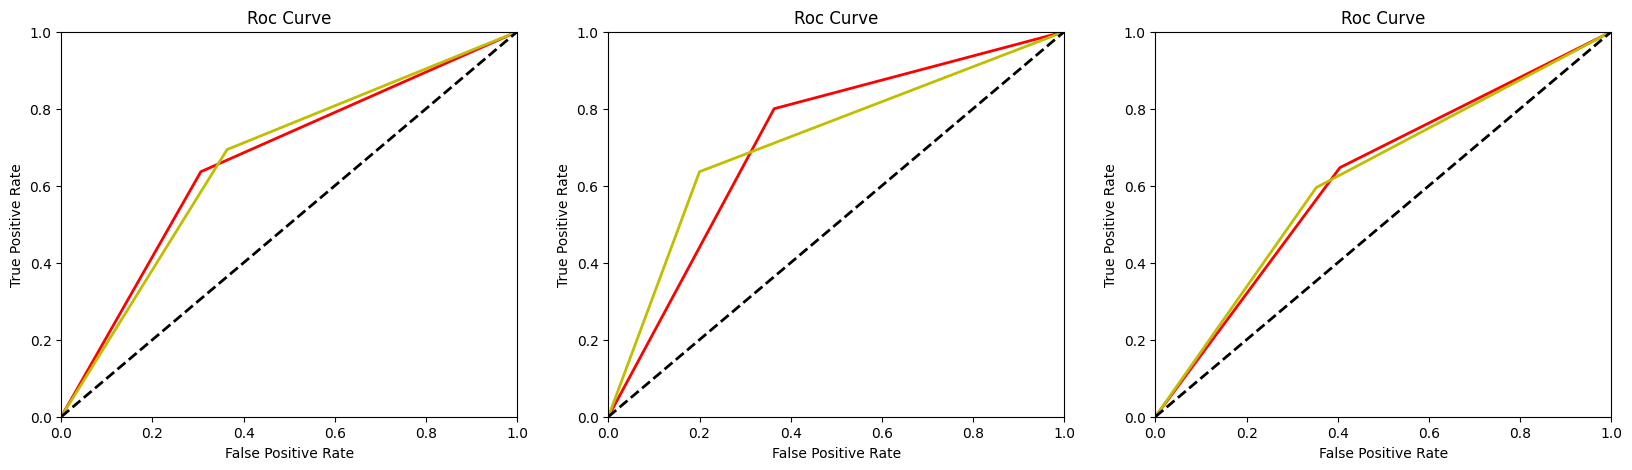

 12%|█▏        | 3/26 [00:11<01:25,  3.72s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-011 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-011/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-011/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  222  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  240  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  226  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7695959595959595 KNeighborsClassifier(metric='euclidean')
cm [[ 7  2]
 [14 47]]
cm.ravel() [ 7  2 14 47]
----- [0.77413479 0.77777778 0.7704918  0.33333333 0.95918367 0.6462585
 0.46666

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.8666666666666666 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[11  7]
 [ 9 43]]
cm.ravel() [11  7  9 43]
----- [0.71901709 0.61111111 0.82692308 0.55       0.86       0.705
 0.57894737 0.84313725 0.71104231 0.71901709 0.38888889 0.14
 0.17307692 0.45       0.40740741] [[11  7]
 [ 9 43]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[10  1]
 [20 39]]
cm.ravel() [10  1 20 39]
----- [0.78505393 0.90909091 0.66101695 0.33333333 0.975      0.65416667
 0.48780488 0.78787879 0.63784183 0.78505393 0.09090909 0.025
 0.33898305 0.66666667 0.32258065] [[10  1]
 [20 39]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 9, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


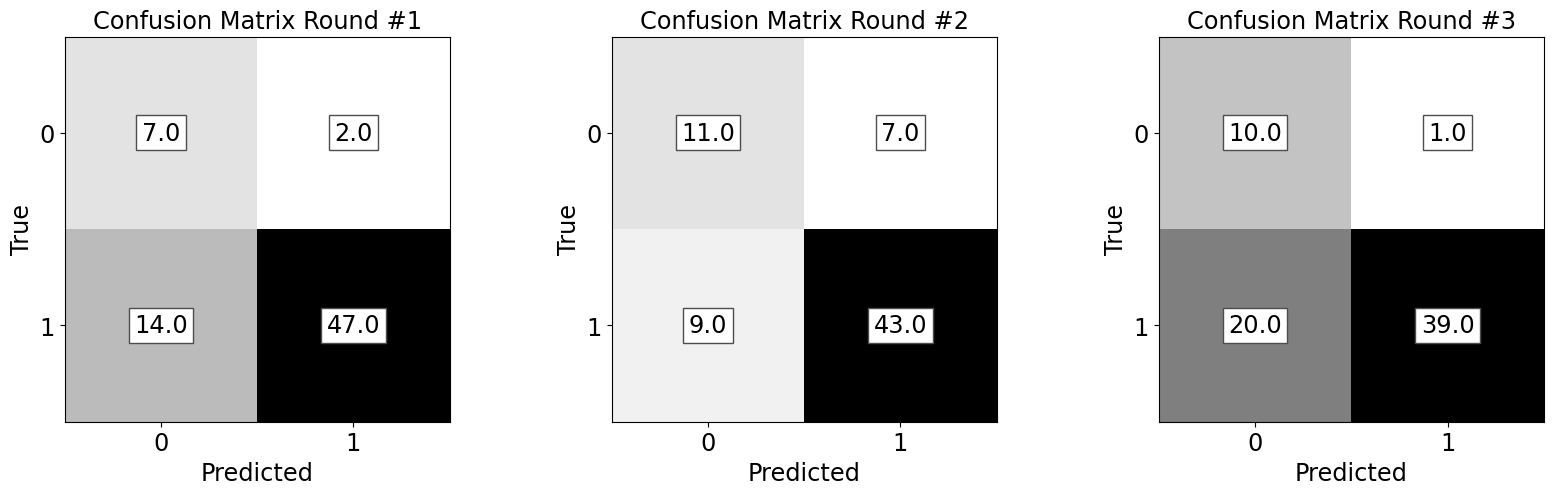

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


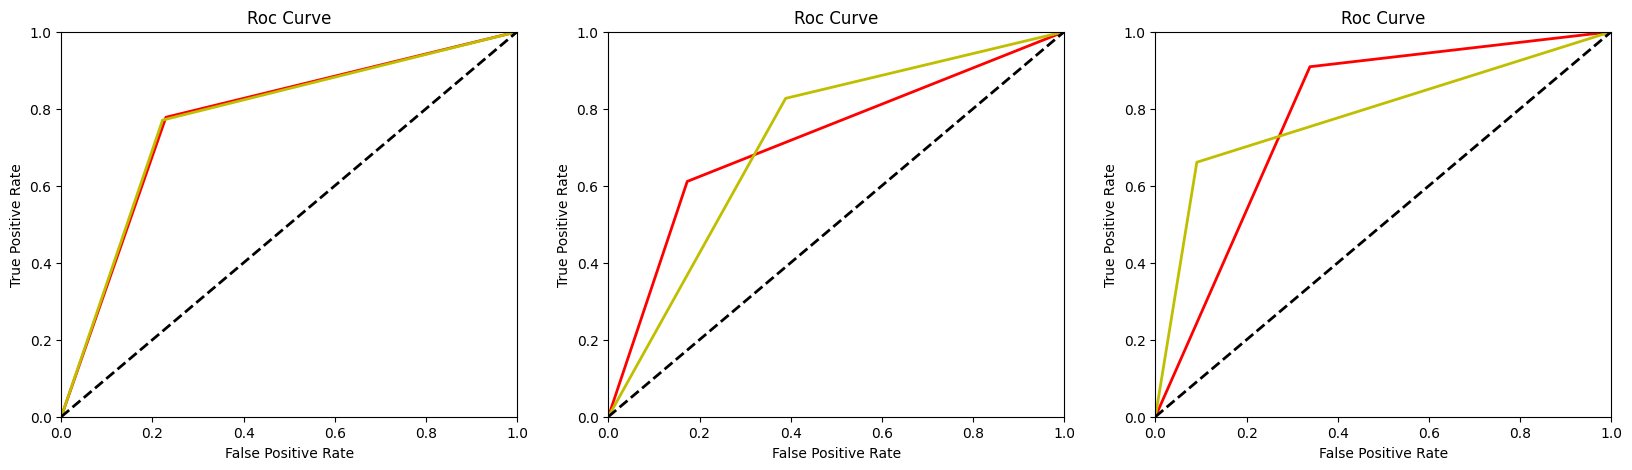

 15%|█▌        | 4/26 [00:18<01:47,  4.90s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-012 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-012/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-012/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  180  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  174  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7611111111111112 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[12  6]
 [11 36]]
cm.ravel() [12  6 11 36]
----- [0.71631206 0.66666667 0.76595745 0.52173913 0.85714286 0.6

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7668016194331984 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[18  7]
 [10 30]]
cm.ravel() [18  7 10 30]
----- [0.735      0.72       0.75       0.64285714 0.81081081 0.72683398
 0.67924528 0.77922078 0.72923303 0.735      0.28       0.18918919
 0.25       0.35714286 0.51428571] [[18  7]
 [10 30]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.8149579831932773 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 9  5]
 [14 36]]
cm.ravel() [ 9  5 14 36]
----- [0.68142857 0.64285714 0.72       0.39130435 0.87804878 0.63467656
 0.48648649 0.79120879 0.63884764 0.68142857 0.35714286 0.12195122
 0.28       0.60869565 0.32142857] [[ 9  5]
 [14 36]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


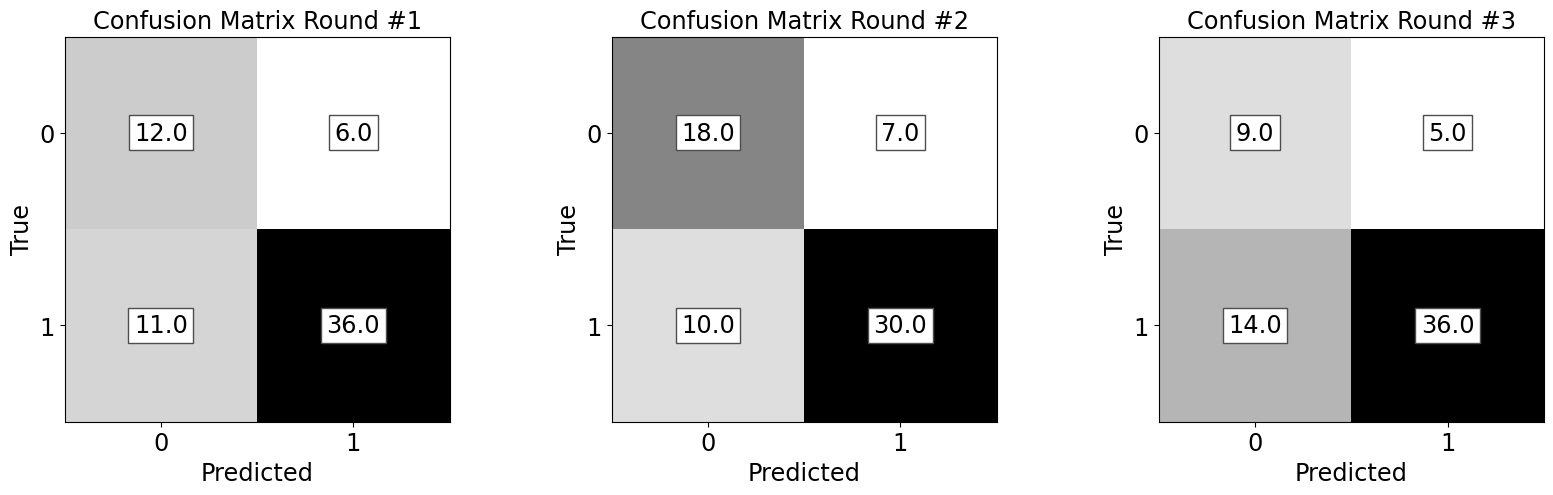

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


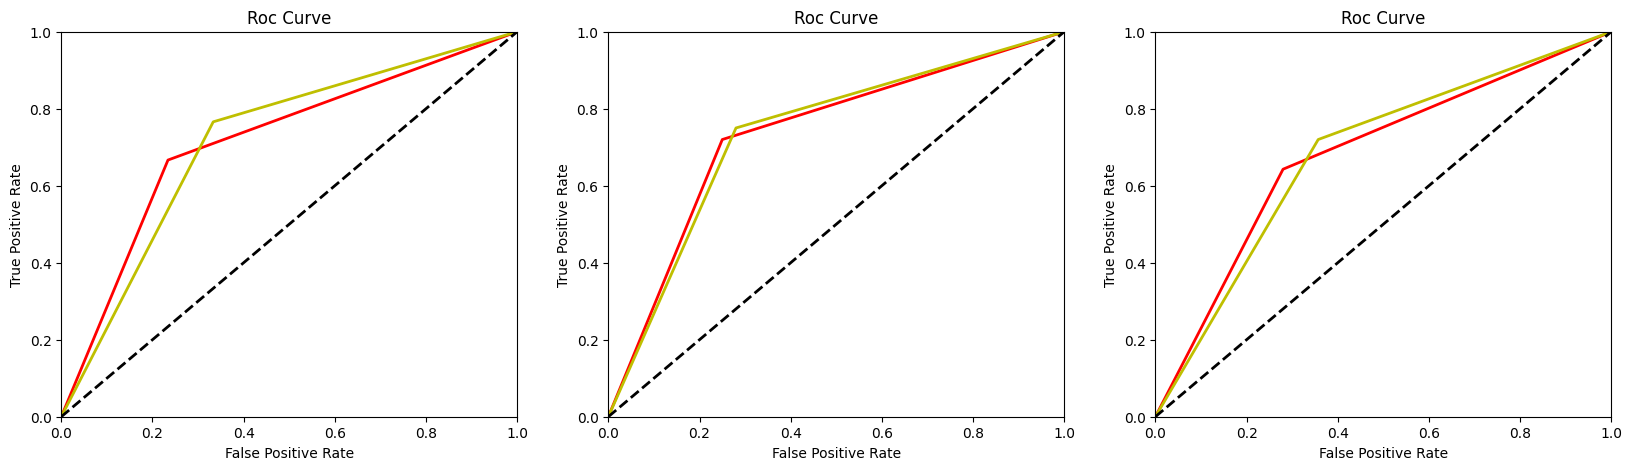

 19%|█▉        | 5/26 [00:22<01:33,  4.46s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-022 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-022/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-022/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  136  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  220  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  136  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  216  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  136  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  224  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.740909090909091 KNeighborsClassifier(metric='manhattan', n_neighbors=9)
cm [[10  3]
 [23 32]]
cm.ravel() [10  3 23 32]
----- [0.67552448 0.76923077 0.58181818 0.3030303  0.91428571 0.60

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7454545454545454 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 7  4]
 [22 35]]
cm.ravel() [ 7  4 22 35]
----- [0.62519936 0.63636364 0.61403509 0.24137931 0.8974359  0.5694076
 0.35       0.72916667 0.53958333 0.62519936 0.36363636 0.1025641
 0.38596491 0.75862069 0.21212121] [[ 7  4]
 [22 35]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 8  7]
 [10 43]]
cm.ravel() [ 8  7 10 43]
----- [0.67232704 0.53333333 0.81132075 0.44444444 0.86       0.65222222
 0.48484848 0.83495146 0.65989997 0.67232704 0.46666667 0.14
 0.18867925 0.55555556 0.32      ] [[ 8  7]
 [10 43]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


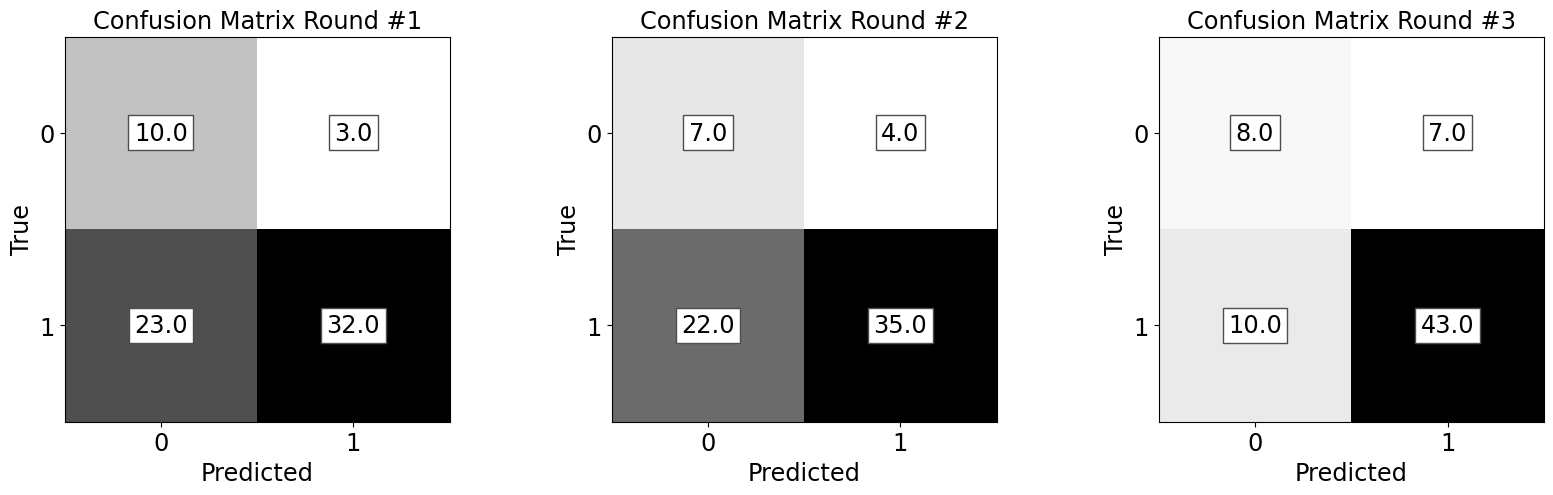

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


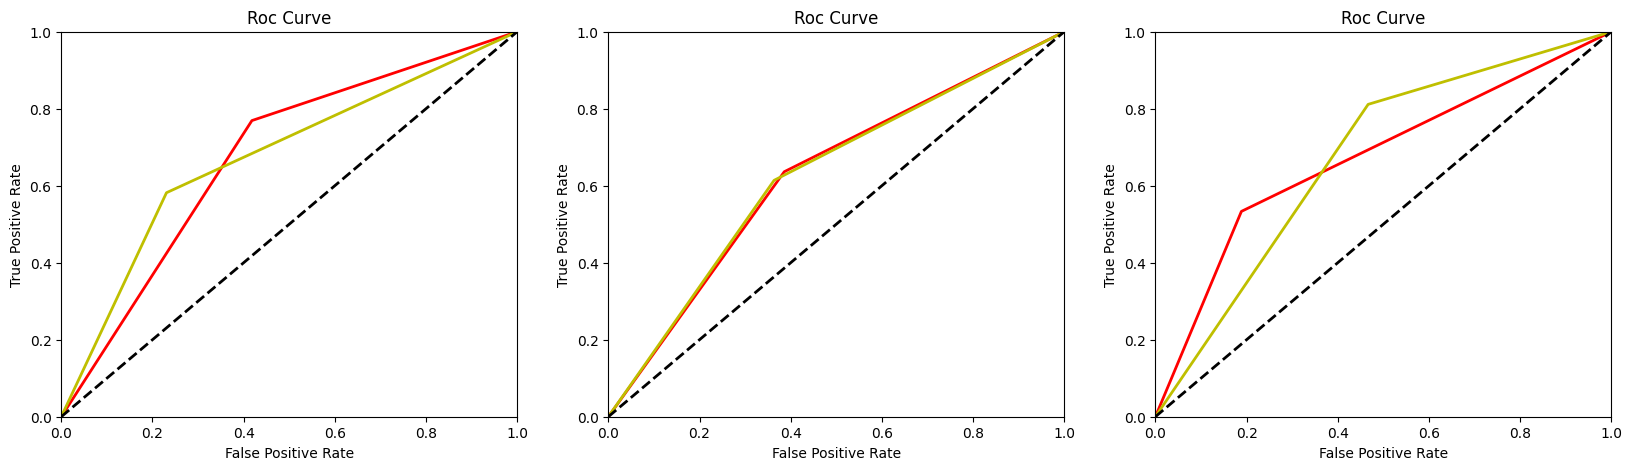

 23%|██▎       | 6/26 [00:26<01:28,  4.45s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-023 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-023/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  202  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  129  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  206  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  130  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  212  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.6532926829268292 KNeighborsClassifier(metric='manhattan')
cm [[ 5  6]
 [29 25]]
cm.ravel() [ 5  6 29 25]
----- [0.45875421 0.45454545 0.46296296 0.14705882 0.80645161 0.47675522
 0.2222

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.6982578397212543 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 5  8]
 [10 42]]
cm.ravel() [ 5  8 10 42]
----- [0.59615385 0.38461538 0.80769231 0.33333333 0.84       0.58666667
 0.35714286 0.82352941 0.59033613 0.59615385 0.61538462 0.16
 0.19230769 0.66666667 0.2173913 ] [[ 5  8]
 [10 42]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7260243632336655 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 6  9]
 [14 35]]
cm.ravel() [ 6  9 14 35]
----- [0.55714286 0.4        0.71428571 0.3        0.79545455 0.54772727
 0.34285714 0.75268817 0.54777266 0.55714286 0.6        0.20454545
 0.28571429 0.7        0.20689655] [[ 6  9]
 [14 35]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


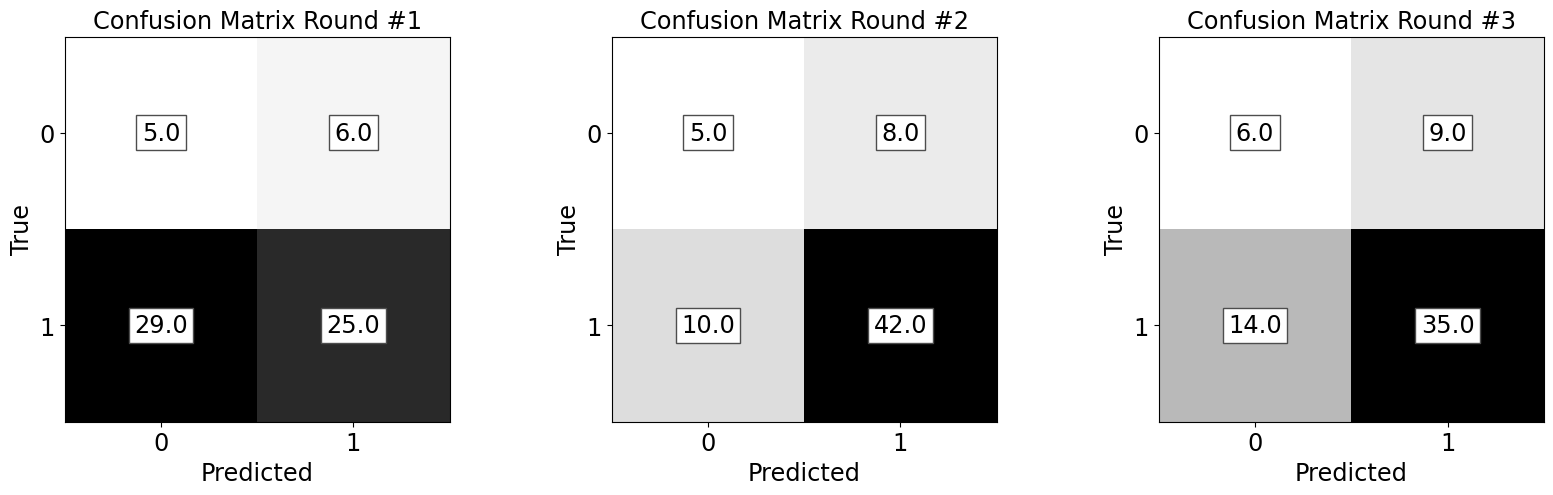

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


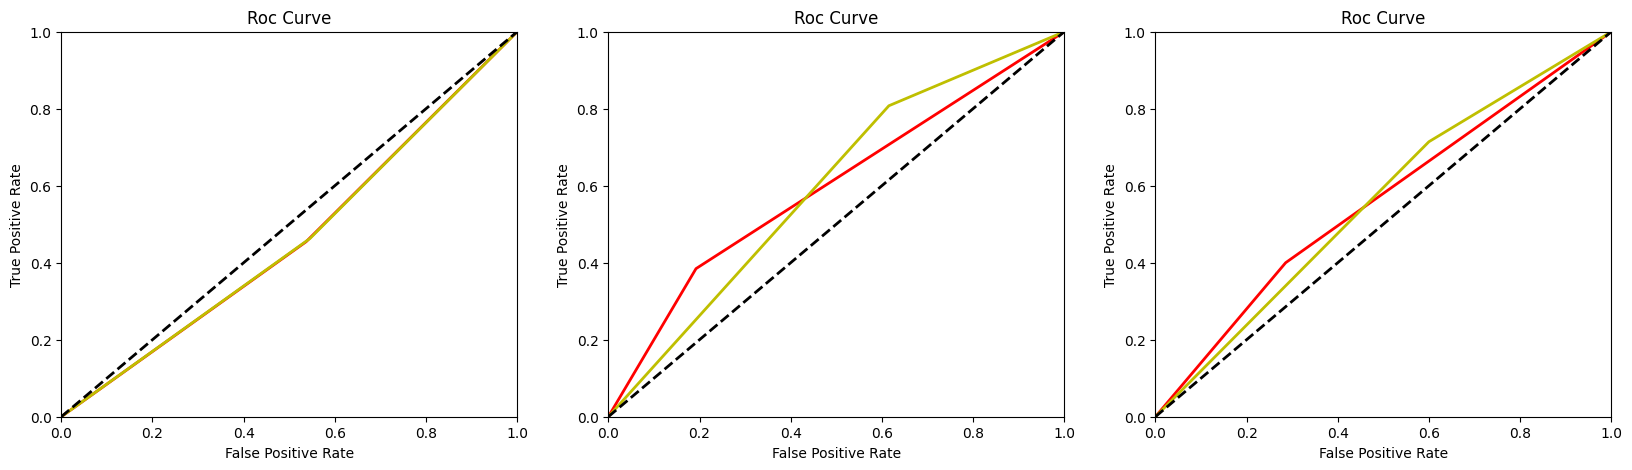

 27%|██▋       | 7/26 [00:31<01:29,  4.72s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-025 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-025/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-025/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  78  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  118  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  78  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  126  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  78  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  128  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7532608695652174 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 3  2]
 [13 21]]
cm.ravel() [ 3  2 13 21]
----- [0.60882353 0.6        0.61764706 0.1875     0.91304348 0.5502

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.784923076923077 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 5  4]
 [ 5 25]]
cm.ravel() [ 5  4  5 25]
----- [0.69444444 0.55555556 0.83333333 0.5        0.86206897 0.68103448
 0.52631579 0.84745763 0.68688671 0.69444444 0.44444444 0.13793103
 0.16666667 0.5        0.35714286] [[ 5  4]
 [ 5 25]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 7  3]
 [12 17]]
cm.ravel() [ 7  3 12 17]
----- [0.64310345 0.7        0.5862069  0.36842105 0.85       0.60921053
 0.48275862 0.69387755 0.58831809 0.64310345 0.3        0.15
 0.4137931  0.63157895 0.31818182] [[ 7  3]
 [12 17]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


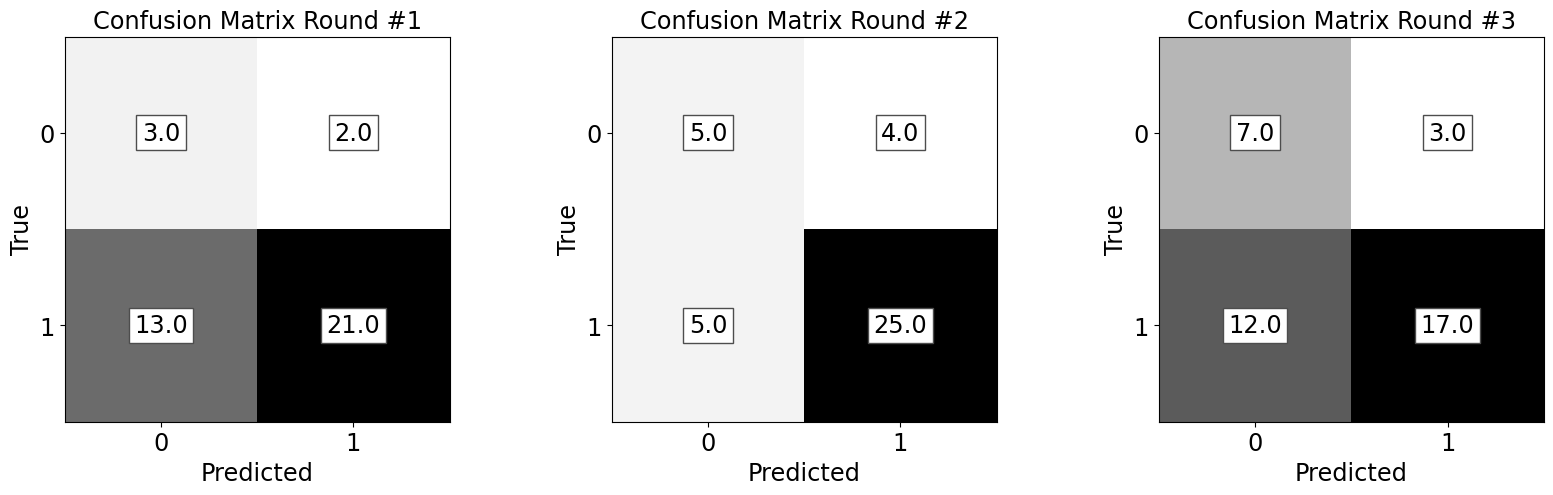

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


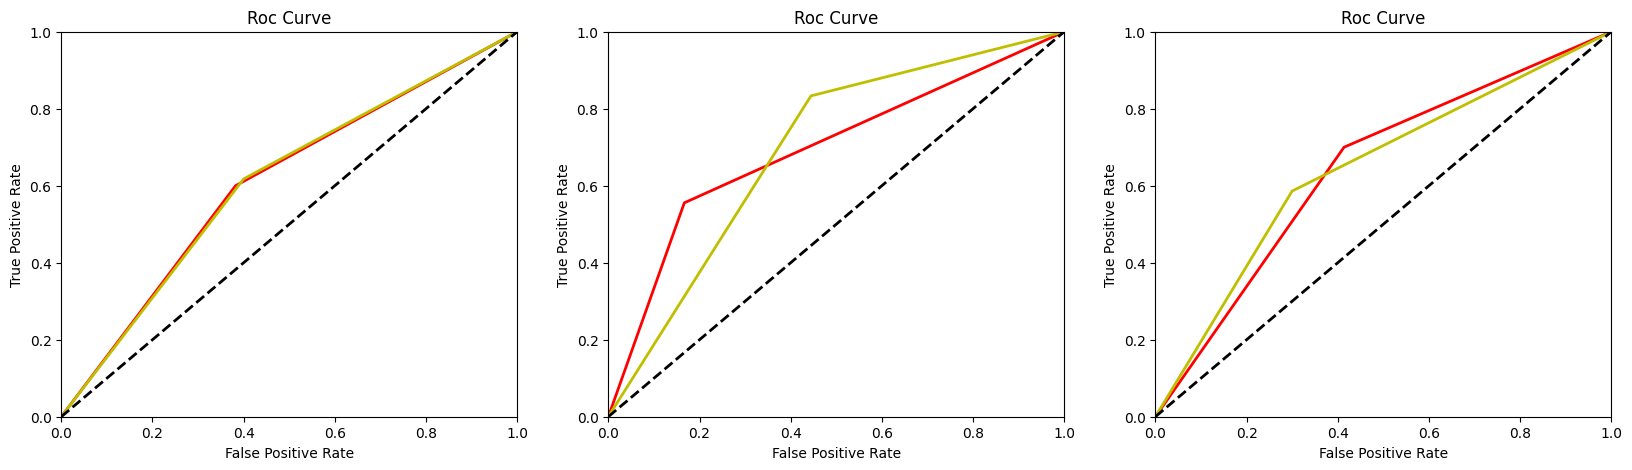

 31%|███       | 8/26 [00:35<01:17,  4.30s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-028 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-028/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-028/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  61  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  104  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  61  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  94  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  62  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  98  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.8071428571428573 KNeighborsClassifier(metric='euclidean', n_neighbors=11)
cm [[ 5  4]
 [ 6 16]]
cm.ravel() [ 5  4  6 16]
----- [0.64141414 0.55555556 0.72727273 0.45454545 0.8        0.62727

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 1  3]
 [11 16]]
cm.ravel() [ 1  3 11 16]
----- [0.4212963  0.25       0.59259259 0.08333333 0.84210526 0.4627193
 0.125      0.69565217 0.41032609 0.4212963  0.75       0.15789474
 0.40740741 0.91666667 0.06666667] [[ 1  3]
 [11 16]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 4  1]
 [13 12]]
cm.ravel() [ 4  1 13 12]
----- [0.64       0.8        0.48       0.23529412 0.92307692 0.57918552
 0.36363636 0.63157895 0.49760766 0.64       0.2        0.07692308
 0.52       0.76470588 0.22222222] [[ 4  1]
 [13 12]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


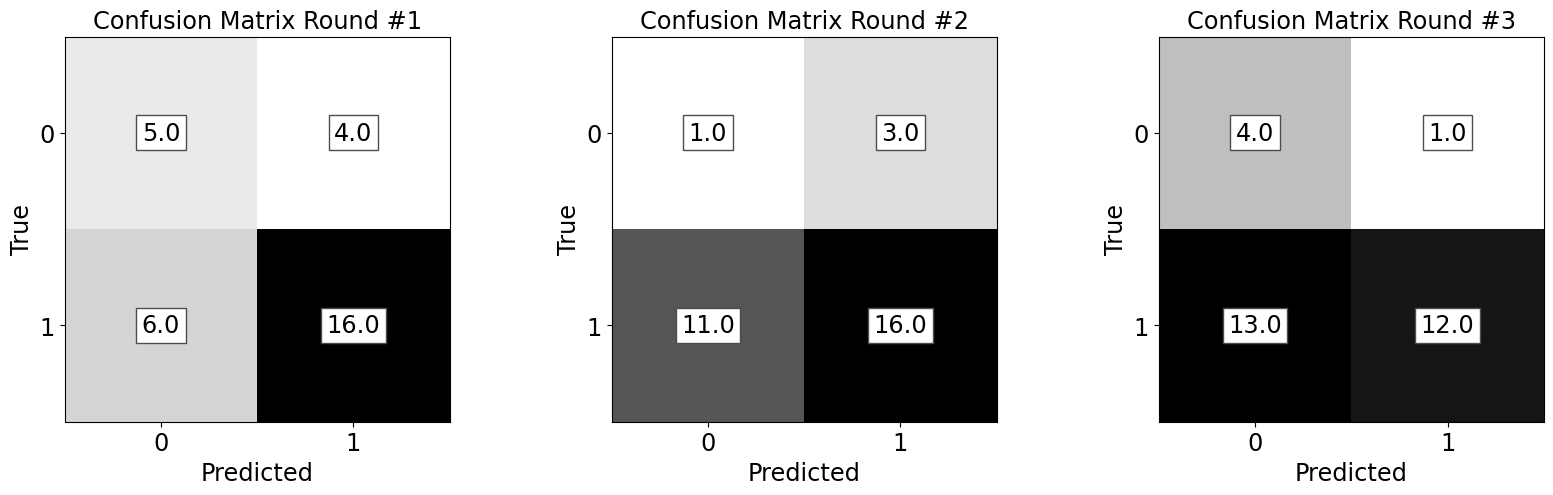

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


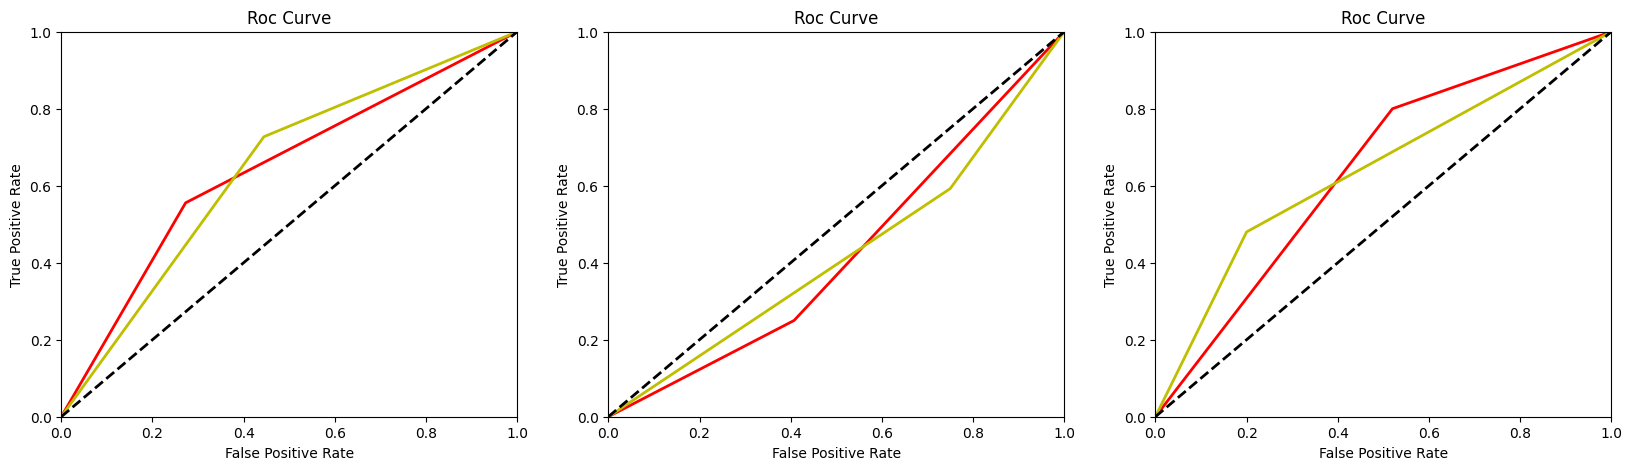

 35%|███▍      | 9/26 [00:38<01:08,  4.01s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=11)
~~~~~~~~~~~~~~~~~ SB-037 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-037/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-037/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  222  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  230  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  140  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  228  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.6364646464646464 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 5  6]
 [22 37]]
cm.ravel() [ 5  6 22 37]
----- [0.54083205 0.45454545 0.62711864 0.18518519 0.86046512 0.

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.6695652173913043 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 4 11]
 [23 32]]
cm.ravel() [ 4 11 23 32]
----- [0.42424242 0.26666667 0.58181818 0.14814815 0.74418605 0.4461671
 0.19047619 0.65306122 0.42176871 0.42424242 0.73333333 0.25581395
 0.41818182 0.85185185 0.10526316] [[ 4 11]
 [23 32]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.720096618357488 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 5  9]
 [23 33]]
cm.ravel() [ 5  9 23 33]
----- [0.47321429 0.35714286 0.58928571 0.17857143 0.78571429 0.48214286
 0.23809524 0.67346939 0.45578231 0.47321429 0.64285714 0.21428571
 0.41071429 0.82142857 0.13513514] [[ 5  9]
 [23 33]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


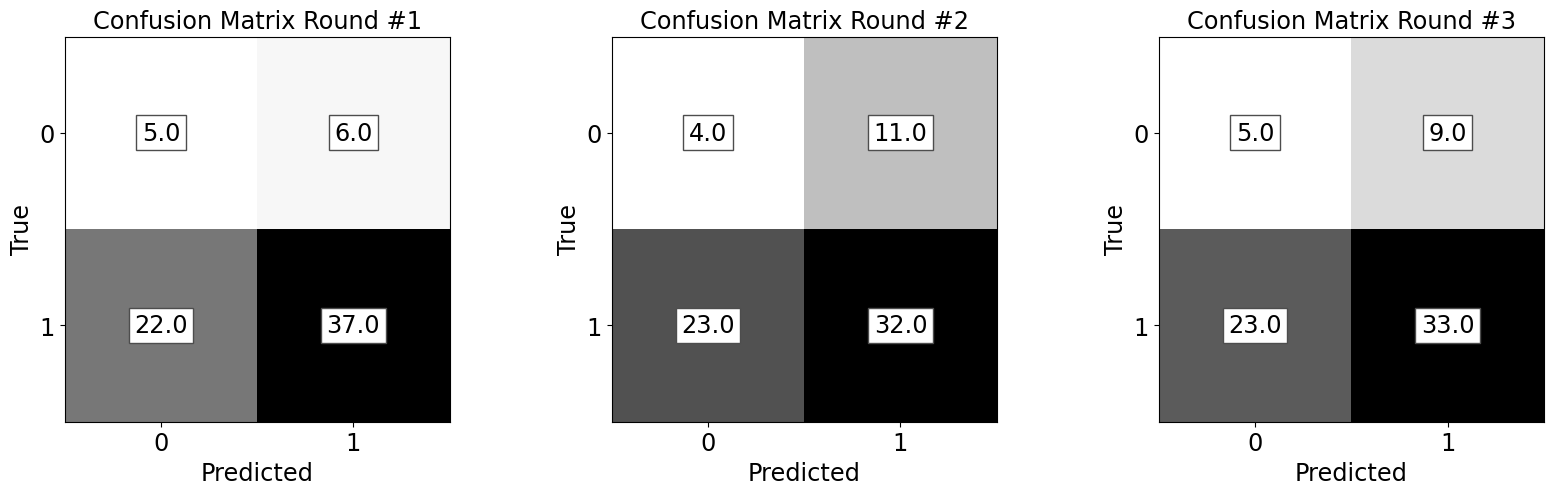

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


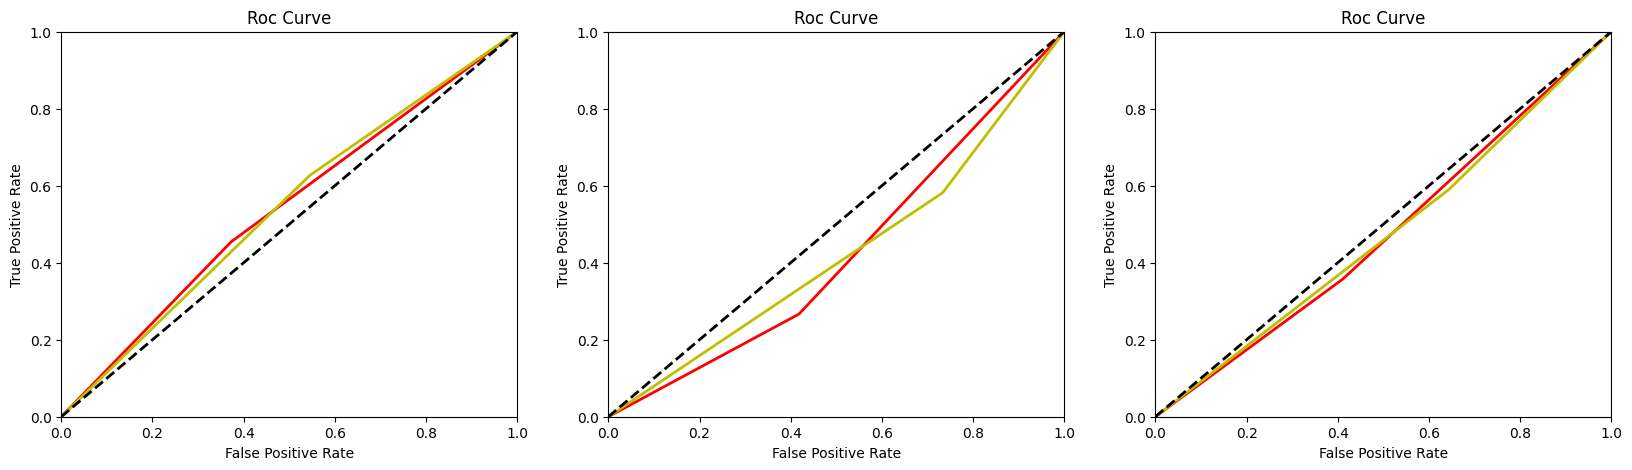

 42%|████▏     | 11/26 [00:44<00:53,  3.60s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-043 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-043/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-043/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  127  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  200  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  127  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  202  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  128  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  210  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.8099999999999999 KNeighborsClassifier(metric='manhattan')
cm [[ 6  5]
 [12 41]]
cm.ravel() [ 6  5 12 41]
----- [0.65951973 0.54545455 0.77358491 0.33333333 0.89130435 0.61231884
 0.4137

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 9  3]
 [21 31]]
cm.ravel() [ 9  3 21 31]
----- [0.67307692 0.75       0.59615385 0.3        0.91176471 0.60588235
 0.42857143 0.72093023 0.57475083 0.67307692 0.25       0.08823529
 0.40384615 0.7        0.27272727] [[ 9  3]
 [21 31]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 9  6]
 [21 27]]
cm.ravel() [ 9  6 21 27]
----- [0.58125    0.6        0.5625     0.3        0.81818182 0.55909091
 0.4        0.66666667 0.53333333 0.58125    0.4        0.18181818
 0.4375     0.7        0.25      ] [[ 9  6]
 [21 27]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


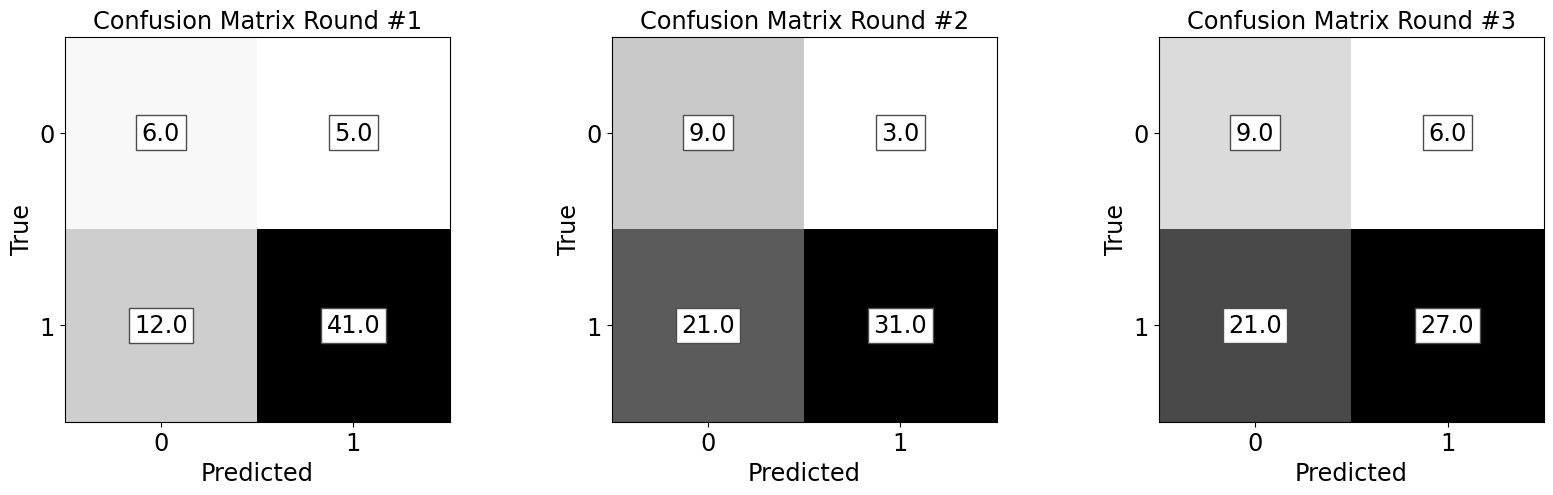

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


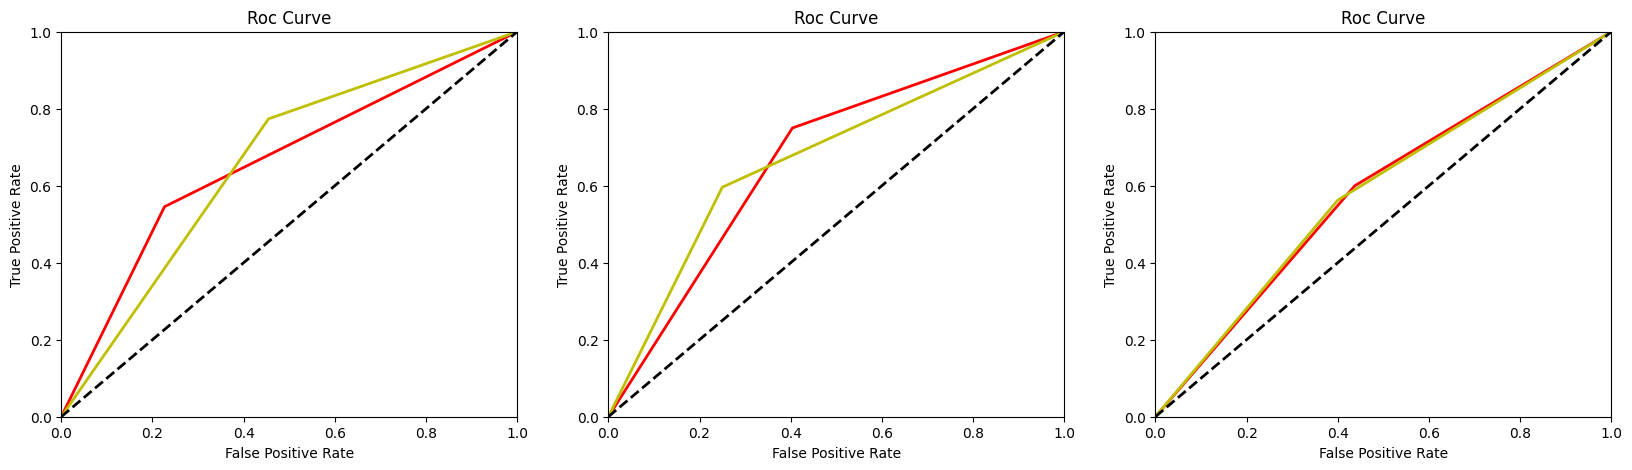

 46%|████▌     | 12/26 [00:48<00:51,  3.68s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan')
~~~~~~~~~~~~~~~~~ SB-056 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-056/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-056/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  127  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  202  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  127  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  192  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  128  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  206  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7967073170731708 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 9  6]
 [14 35]]
cm.ravel() [ 9  6 14 35]
----- [0.65714286 0.6        0.71428571 0.39130435 0.85365854 0.62248144
 0.4736

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 6  4]
 [11 43]]
cm.ravel() [ 6  4 11 43]
----- [0.69814815 0.6        0.7962963  0.35294118 0.91489362 0.6339174
 0.44444444 0.85148515 0.6479648  0.69814815 0.4        0.08510638
 0.2037037  0.64705882 0.28571429] [[ 6  4]
 [11 43]]
* 1-----------kfold--------------- 2 ------------
---K-NN--- 0.8692218350754934 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[12  4]
 [15 32]]
cm.ravel() [12  4 15 32]
----- [0.71542553 0.75       0.68085106 0.44444444 0.88888889 0.66666667
 0.55813953 0.77108434 0.66461194 0.71542553 0.25       0.11111111
 0.31914894 0.55555556 0.38709677] [[12  4]
 [15 32]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


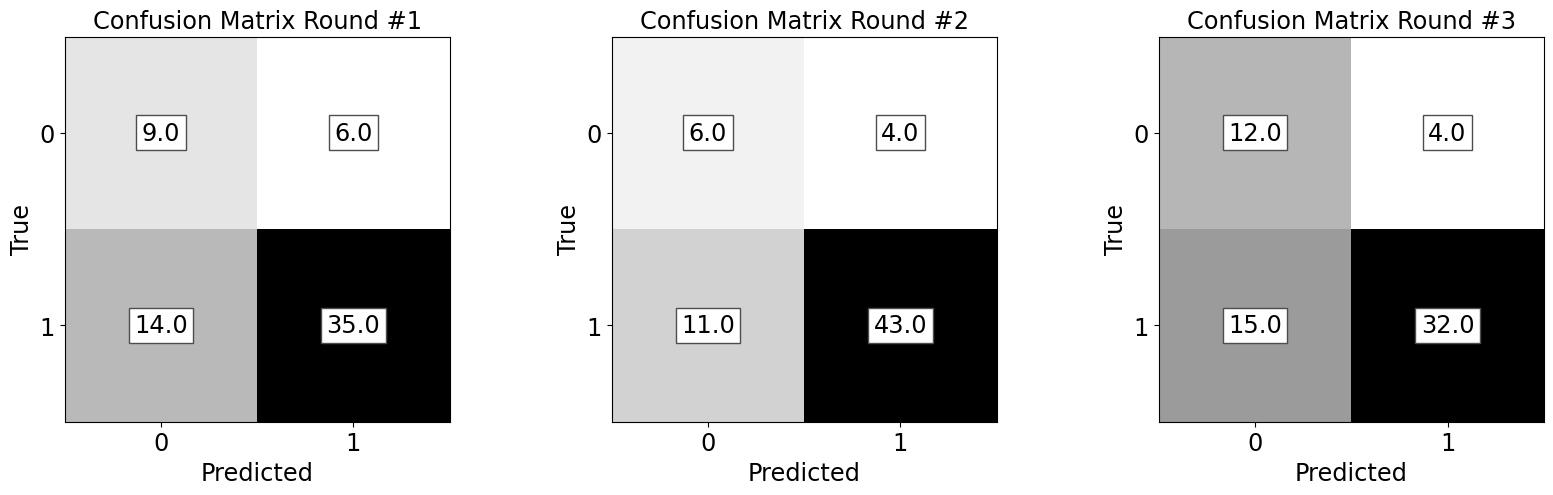

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


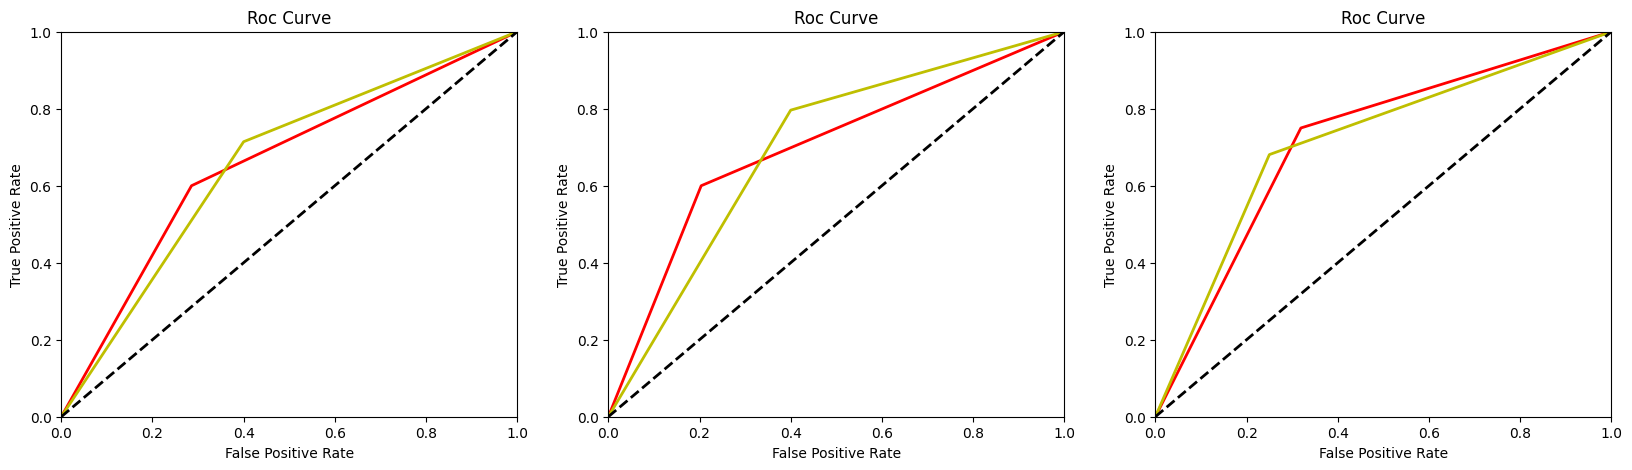

 50%|█████     | 13/26 [00:52<00:49,  3.80s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-059 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-059/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-059/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  135  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  228  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  135  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  225  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  136  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  222  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.67487922705314 KNeighborsClassifier(metric='euclidean', n_neighbors=3, weights='distance')
cm [[ 6  5]
 [24 33]]
cm.ravel() [ 6  5 24 33]
----- [0.56220096 0.54545455 0.57894737 0.2    

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7022222222222222 KNeighborsClassifier(metric='euclidean', n_neighbors=3, weights='distance')
cm [[ 4 10]
 [17 37]]
cm.ravel() [ 4 10 17 37]
----- [0.48544974 0.28571429 0.68518519 0.19047619 0.78723404 0.48885512
 0.22857143 0.73267327 0.48062235 0.48544974 0.71428571 0.21276596
 0.31481481 0.80952381 0.12903226] [[ 4 10]
 [17 37]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 2  5]
 [22 38]]
cm.ravel() [ 2  5 22 38]
----- [0.45952381 0.28571429 0.63333333 0.08333333 0.88372093 0.48352713
 0.12903226 0.73786408 0.43344817 0.45952381 0.71428571 0.11627907
 0.36666667 0.91666667 0.06896552] [[ 2  5]
 [22 38]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'distance'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


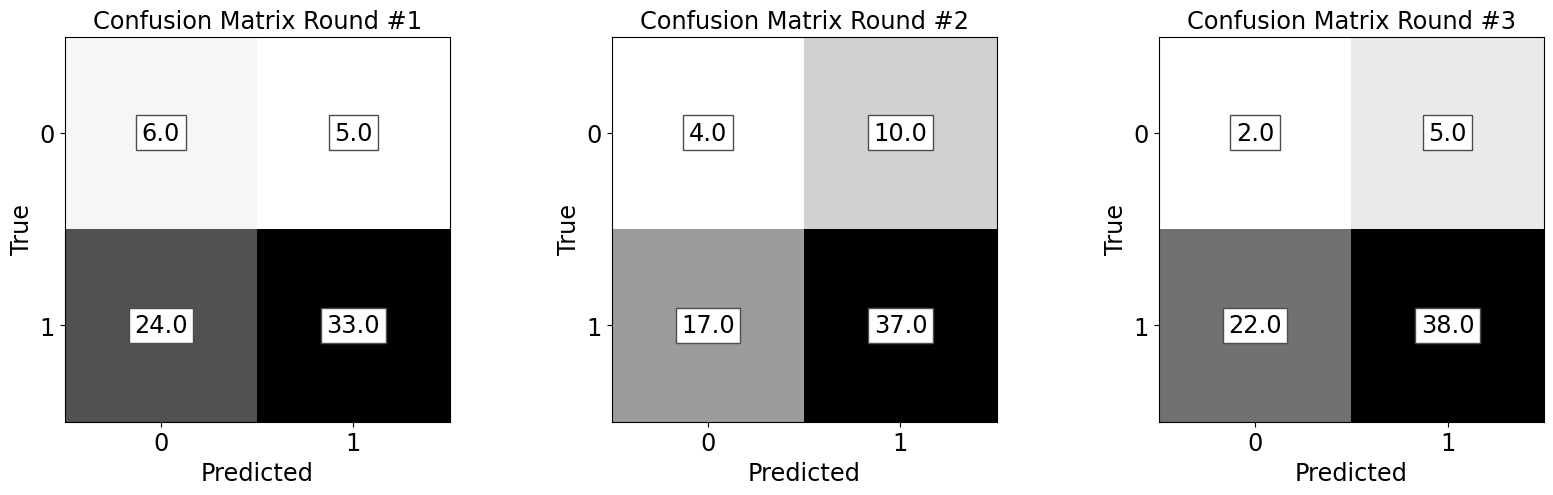

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


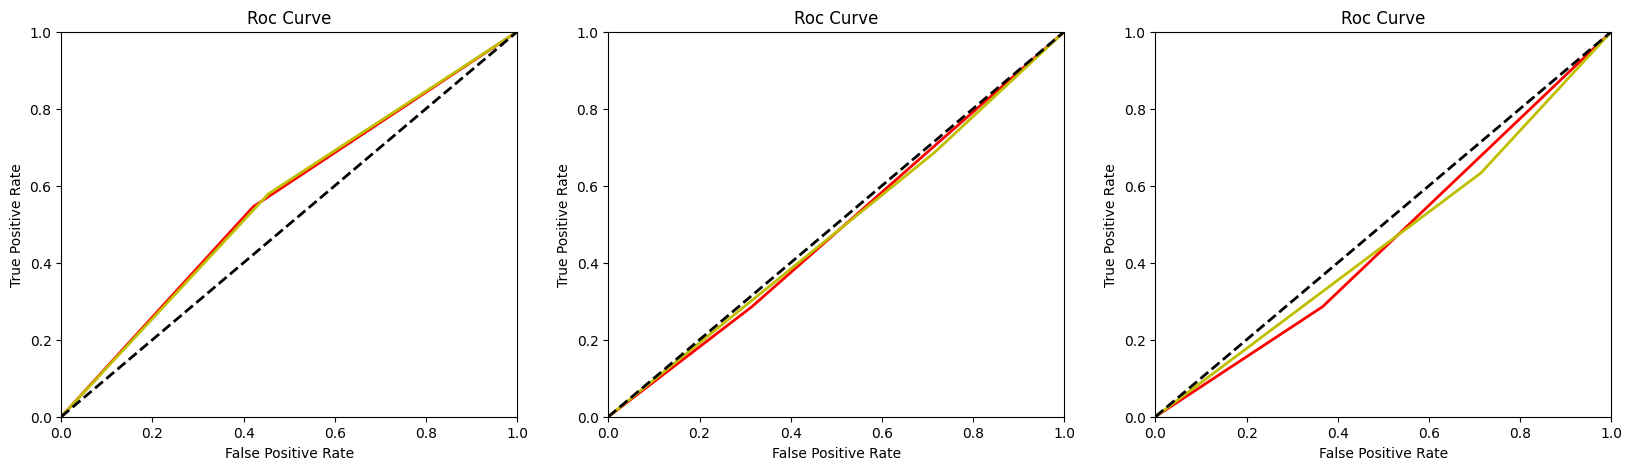

 54%|█████▍    | 14/26 [00:58<00:51,  4.27s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3, weights='distance')
~~~~~~~~~~~~~~~~~ SB-060 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-060/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-060/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  58  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  96  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  59  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  96  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  59  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  96  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.8468421052631578 KNeighborsClassifier(metric='manhattan', n_neighbors=9)
cm [[ 6  0]
 [ 6 18]]
cm.ravel() [ 6  0  6 18]
----- [0.875      1.         0.75       0.5        

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.888421052631579 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 2  3]
 [ 4 20]]
cm.ravel() [ 2  3  4 20]
----- [0.61666667 0.4        0.83333333 0.33333333 0.86956522 0.60144928
 0.36363636 0.85106383 0.6073501  0.61666667 0.6        0.13043478
 0.16666667 0.66666667 0.22222222] [[ 2  3]
 [ 4 20]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 3  2]
 [ 7 17]]
cm.ravel() [ 3  2  7 17]
----- [0.65416667 0.6        0.70833333 0.3        0.89473684 0.59736842
 0.4        0.79069767 0.59534884 0.65416667 0.4        0.10526316
 0.29166667 0.7        0.25      ] [[ 3  2]
 [ 7 17]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


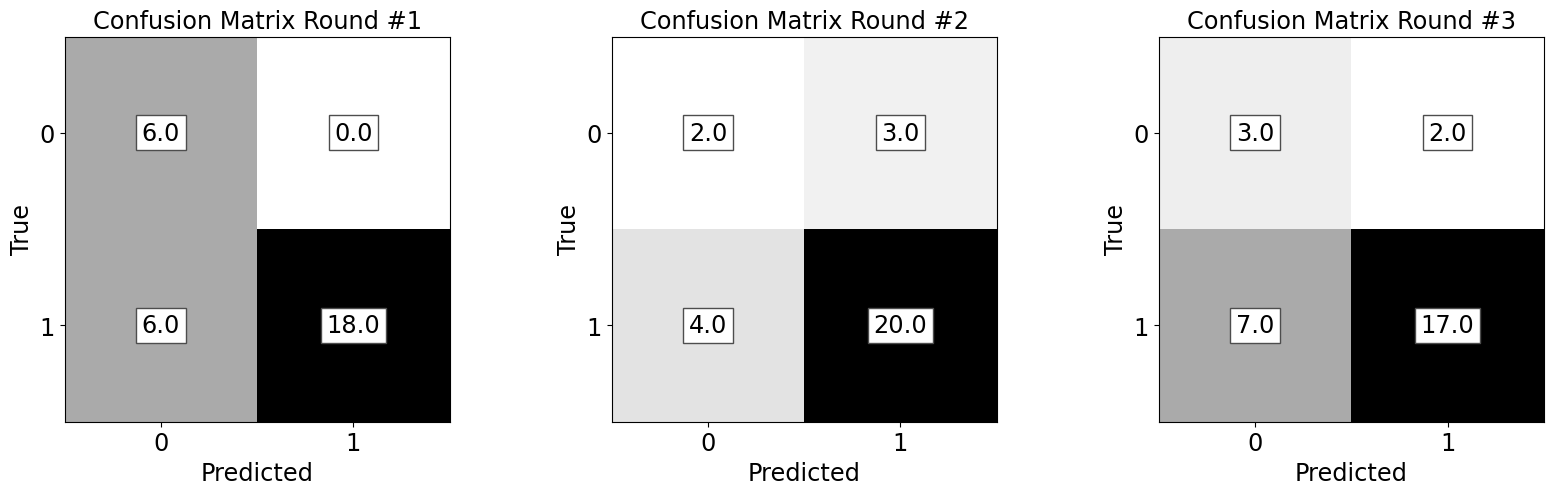

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


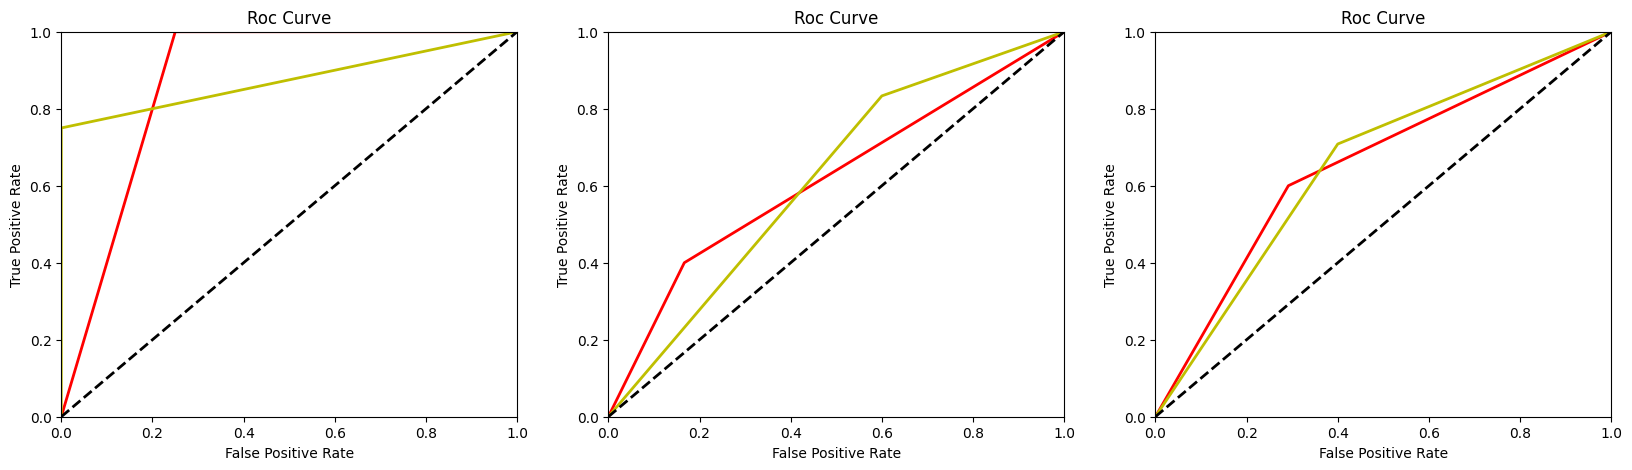

 58%|█████▊    | 15/26 [01:01<00:44,  4.03s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-070 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-070/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-070/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  134  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  226  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  135  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  230  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  135  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  230  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7128502415458937 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 2  7]
 [24 35]]
cm.ravel() [ 2  7 24 35]
----- [0.40772128 0.22222222 0.59322034 0.07692308 0.83333333 0.4

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 3  8]
 [17 39]]
cm.ravel() [ 3  8 17 39]
----- [0.48457792 0.27272727 0.69642857 0.15       0.82978723 0.48989362
 0.19354839 0.75728155 0.47541497 0.48457792 0.72727273 0.17021277
 0.30357143 0.85       0.10714286] [[ 3  8]
 [17 39]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 3  7]
 [26 31]]
cm.ravel() [ 3  7 26 31]
----- [0.42192982 0.3        0.54385965 0.10344828 0.81578947 0.45961887
 0.15384615 0.65263158 0.40323887 0.42192982 0.7        0.18421053
 0.45614035 0.89655172 0.08333333] [[ 3  7]
 [26 31]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


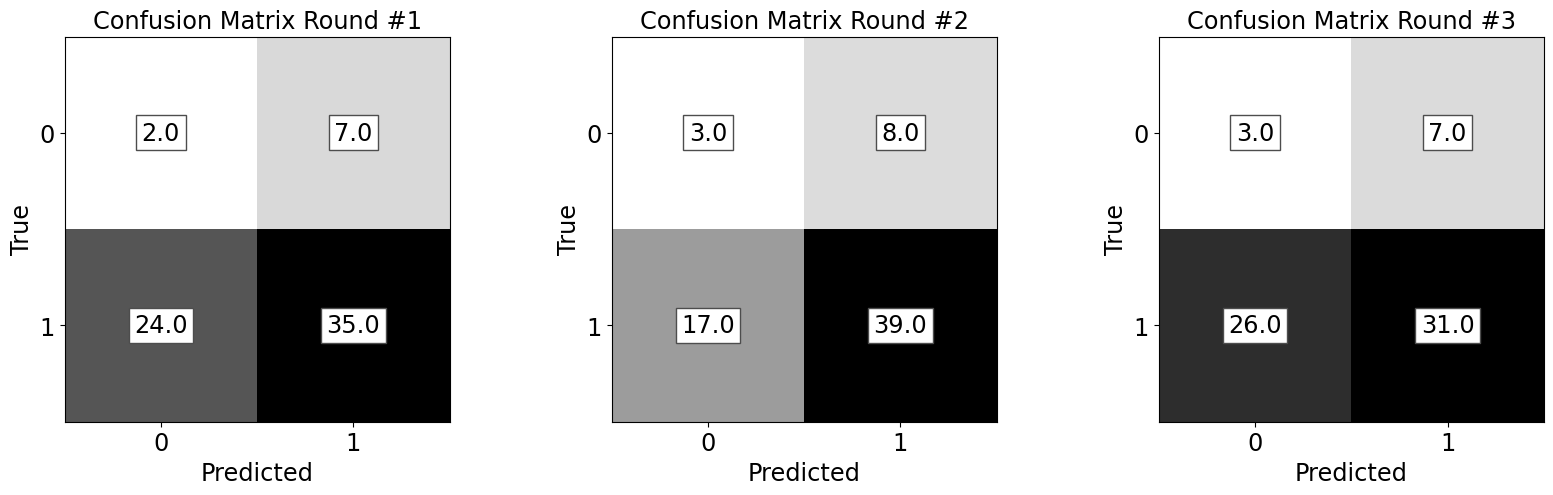

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


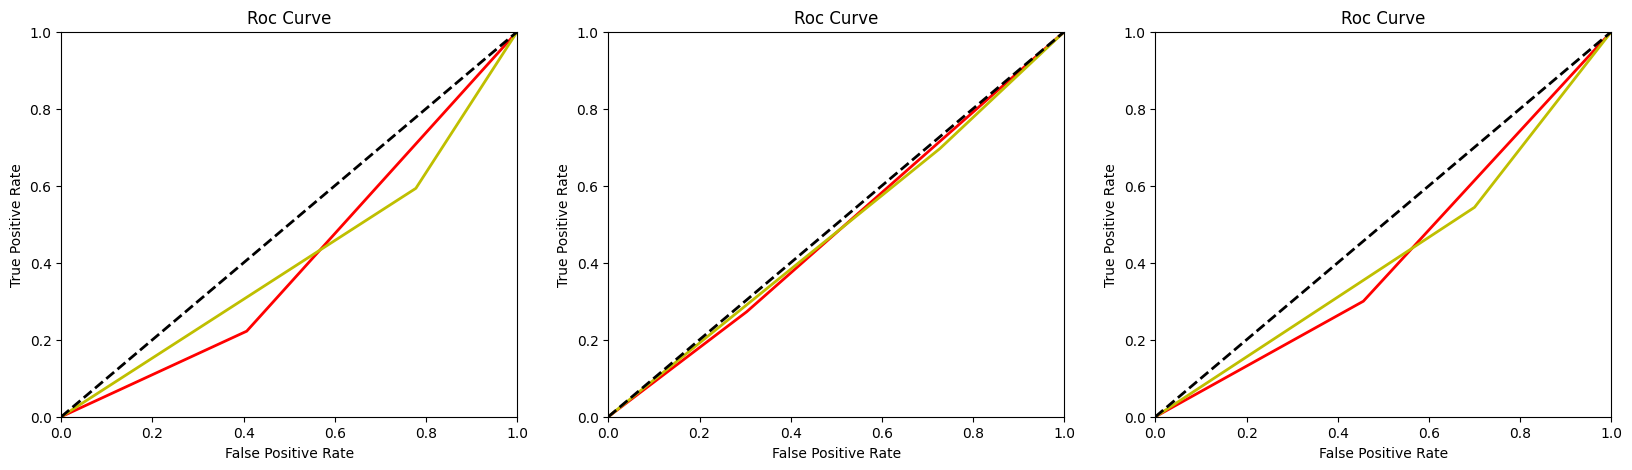

 62%|██████▏   | 16/26 [01:05<00:40,  4.05s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-071 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-071/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-071/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  82  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  138  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  83  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  128  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  83  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  136  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.8248677248677249 KNeighborsClassifier(metric='manhattan')
cm [[ 3  3]
 [10 26]]
cm.ravel() [ 3  3 10 26]
----- [0.61111111 0.5        0.72222222 0.23076923 0.89655172 0.56366048
 0.3157894

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 5  4]
 [ 3 29]]
cm.ravel() [ 5  4  3 29]
----- [0.73090278 0.55555556 0.90625    0.625      0.87878788 0.75189394
 0.58823529 0.89230769 0.74027149 0.73090278 0.44444444 0.12121212
 0.09375    0.375      0.41666667] [[ 5  4]
 [ 3 29]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 4  0]
 [ 7 30]]
cm.ravel() [ 4  0  7 30]
----- [0.90540541 1.         0.81081081 0.36363636 1.         0.68181818
 0.53333333 0.89552239 0.71442786 0.90540541 0.         0.
 0.18918919 0.63636364 0.36363636] [[ 4  0]
 [ 7 30]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


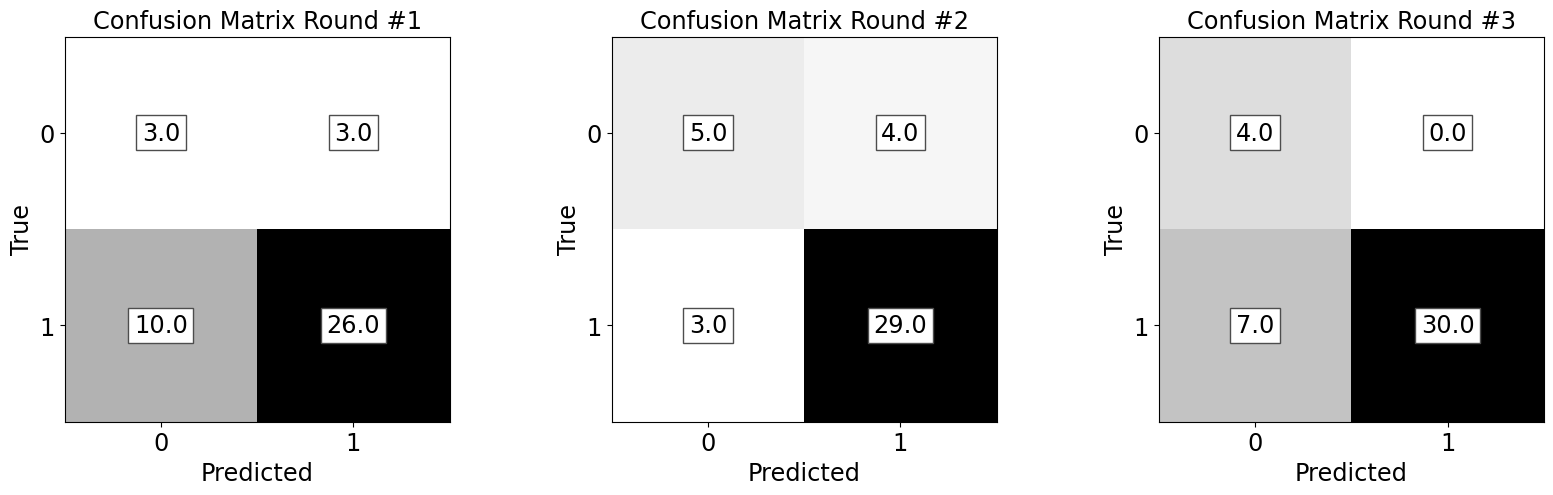

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


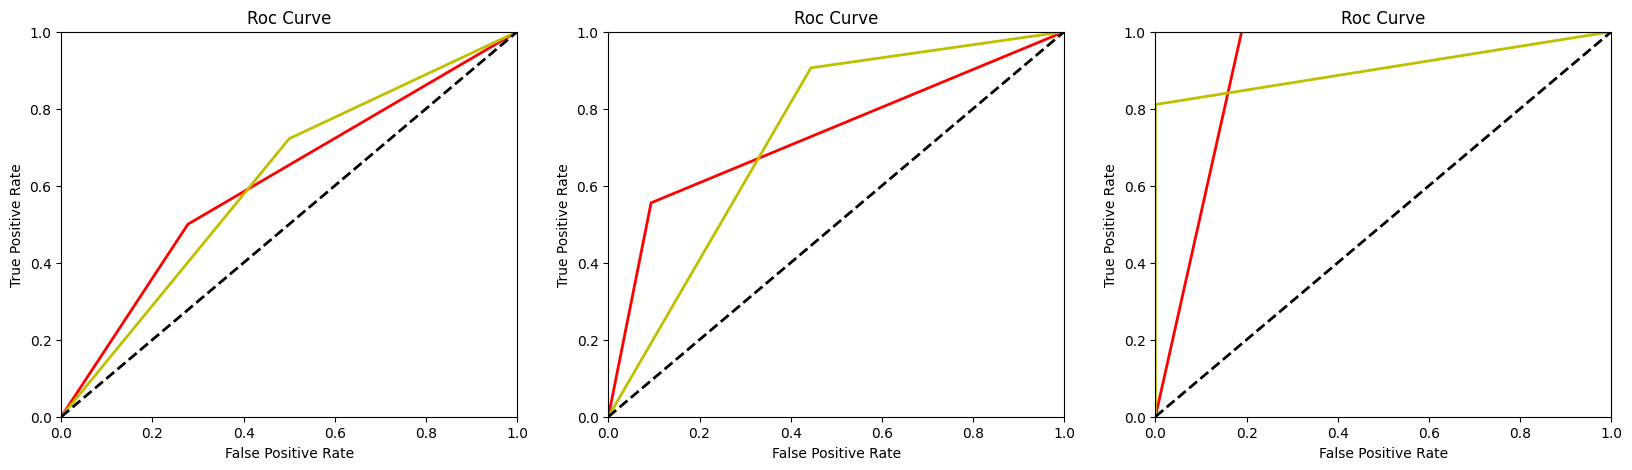

 65%|██████▌   | 17/26 [01:11<00:40,  4.54s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan')
~~~~~~~~~~~~~~~~~ SB-073 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-073/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-073/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  107  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  164  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  107  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  158  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  108  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  158  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7316287878787878 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 9  7]
 [15 23]]
cm.ravel() [ 9  7 15 23]
----- [0.58388158 0.5625     0.60526316 0.375      0.76666667 0.57083333
 0.45  

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7336693548387097 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 5  8]
 [11 30]]
cm.ravel() [ 5  8 11 30]
----- [0.55816135 0.38461538 0.73170732 0.3125     0.78947368 0.55098684
 0.34482759 0.75949367 0.55216063 0.55816135 0.61538462 0.21052632
 0.26829268 0.6875     0.20833333] [[ 5  8]
 [11 30]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 9  3]
 [16 25]]
cm.ravel() [ 9  3 16 25]
----- [0.67987805 0.75       0.6097561  0.36       0.89285714 0.62642857
 0.48648649 0.72463768 0.60556208 0.67987805 0.25       0.10714286
 0.3902439  0.64       0.32142857] [[ 9  3]
 [16 25]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


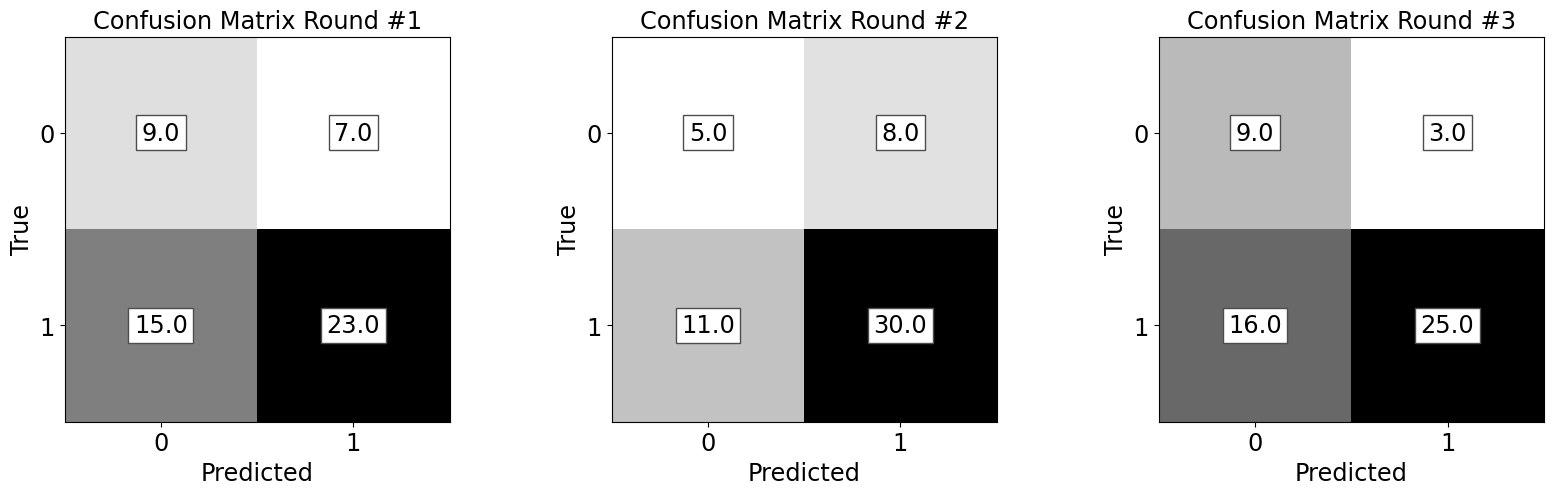

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


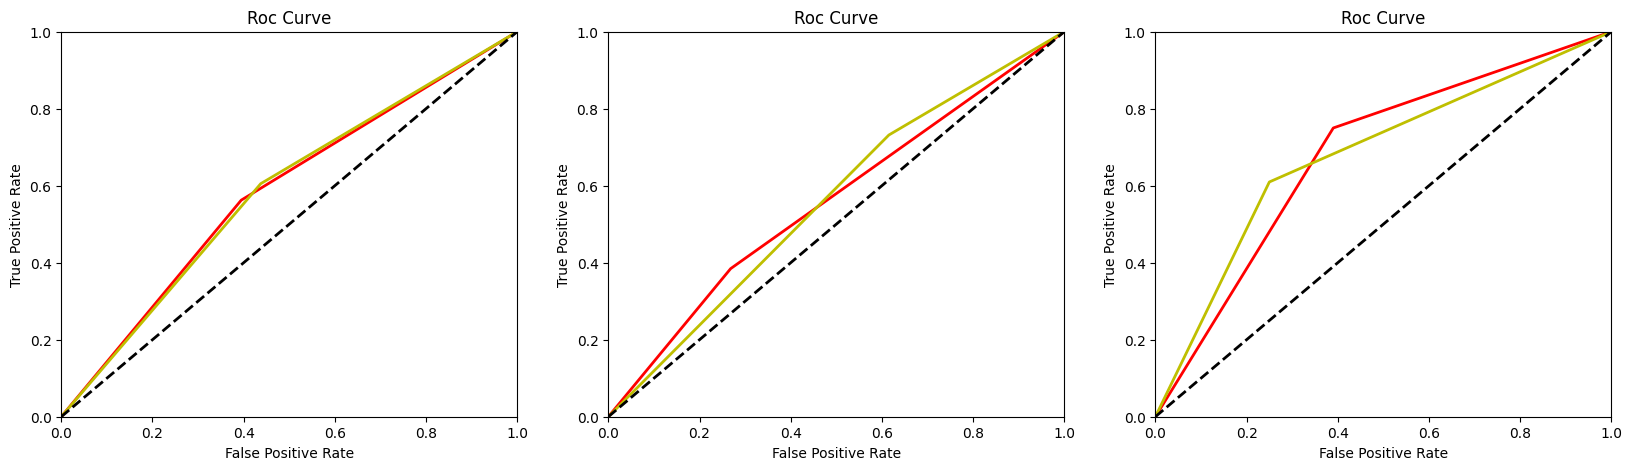

 69%|██████▉   | 18/26 [01:15<00:34,  4.26s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-078 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-078/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-078/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  102  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  144  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  102  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  142  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  102  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  142  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7975369458128079 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[ 7  9]
 [ 3 32]]
cm.ravel() [ 7  9  3 32]
----- [0.67589286 0.4375     0.91428571 0.7        0.7804878  0.7

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.8295566502463053 KNeighborsClassifier(metric='euclidean')
cm [[12  3]
 [14 22]]
cm.ravel() [12  3 14 22]
----- [0.70555556 0.8        0.61111111 0.46153846 0.88       0.67076923
 0.58536585 0.72131148 0.65333866 0.70555556 0.2        0.12
 0.38888889 0.53846154 0.4137931 ] [[12  3]
 [14 22]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[13  2]
 [10 26]]
cm.ravel() [13  2 10 26]
----- [0.79444444 0.86666667 0.72222222 0.56521739 0.92857143 0.74689441
 0.68421053 0.8125     0.74835526 0.79444444 0.13333333 0.07142857
 0.27777778 0.43478261 0.52      ] [[13  2]
 [10 26]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


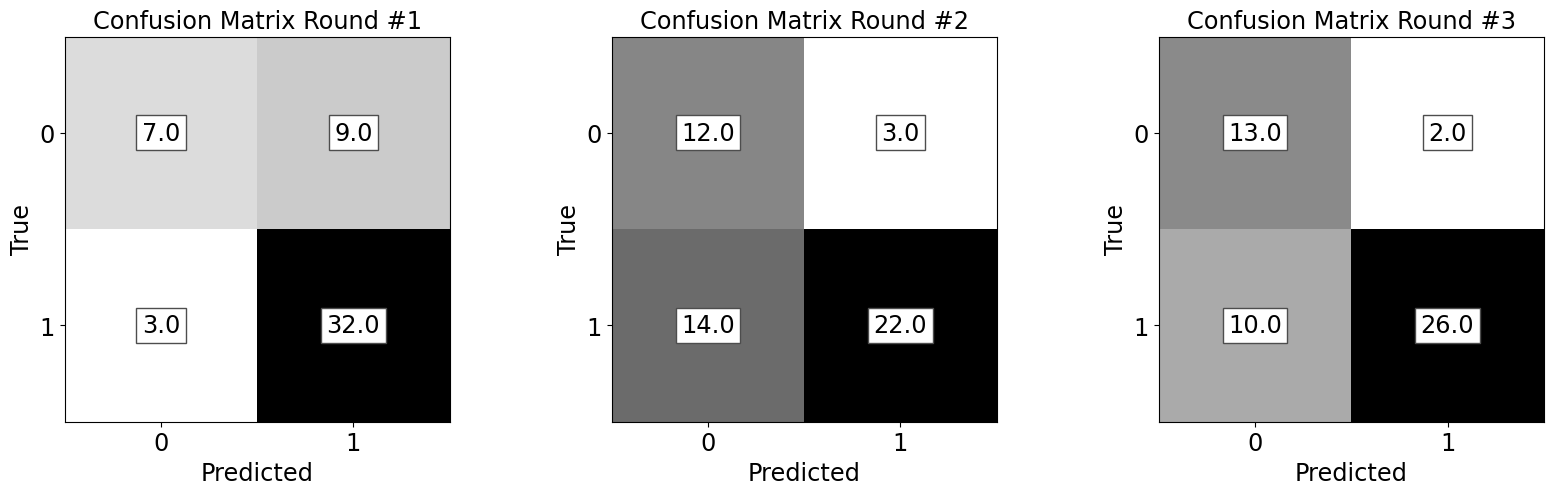

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


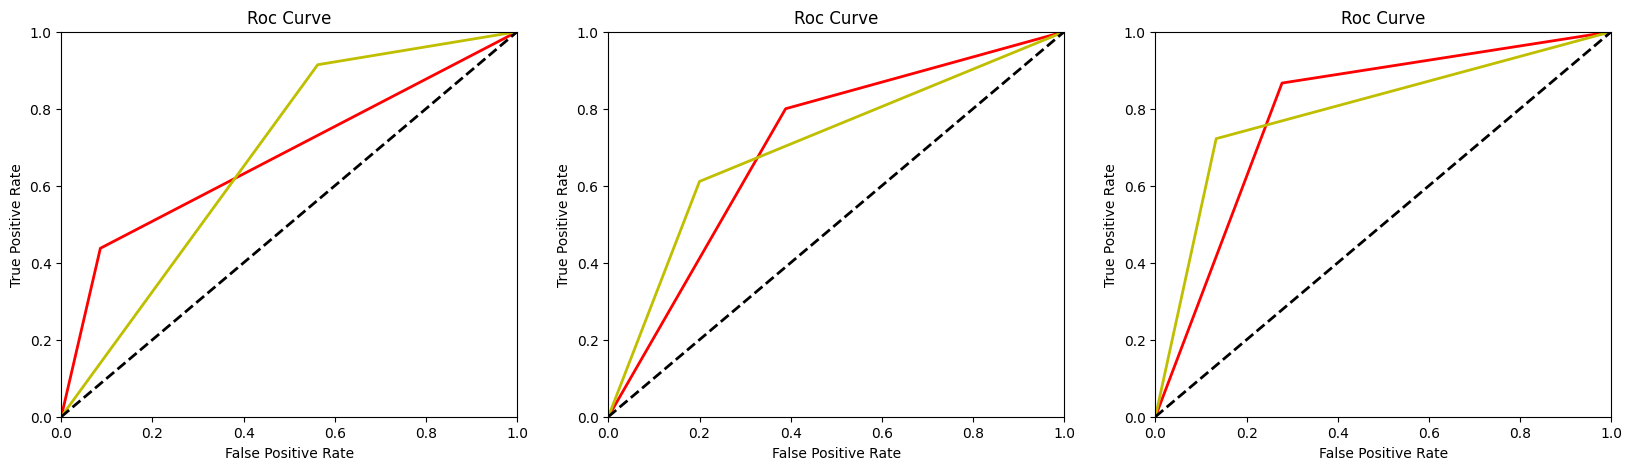

 73%|███████▎  | 19/26 [01:19<00:28,  4.12s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean')
~~~~~~~~~~~~~~~~~ SB-079 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-079/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-079/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  94  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  152  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  95  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  160  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  95  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  148  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7303225806451612 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 3  6]
 [11 28]]
cm.ravel() [ 3  6 11 28]
----- [0.52564103 0.33333333 0.71794872 0.21428571 0.82352941 0.51890756
 0.2608695

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7875 KNeighborsClassifier(metric='euclidean', n_neighbors=3)
cm [[10  2]
 [ 9 26]]
cm.ravel() [10  2  9 26]
----- [0.78809524 0.83333333 0.74285714 0.52631579 0.92857143 0.72744361
 0.64516129 0.82539683 0.73527906 0.78809524 0.16666667 0.07142857
 0.25714286 0.47368421 0.47619048] [[10  2]
 [ 9 26]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 3  3]
 [11 30]]
cm.ravel() [ 3  3 11 30]
----- [0.61585366 0.5        0.73170732 0.21428571 0.90909091 0.56168831
 0.3        0.81081081 0.55540541 0.61585366 0.5        0.09090909
 0.26829268 0.78571429 0.17647059] [[ 3  3]
 [11 30]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


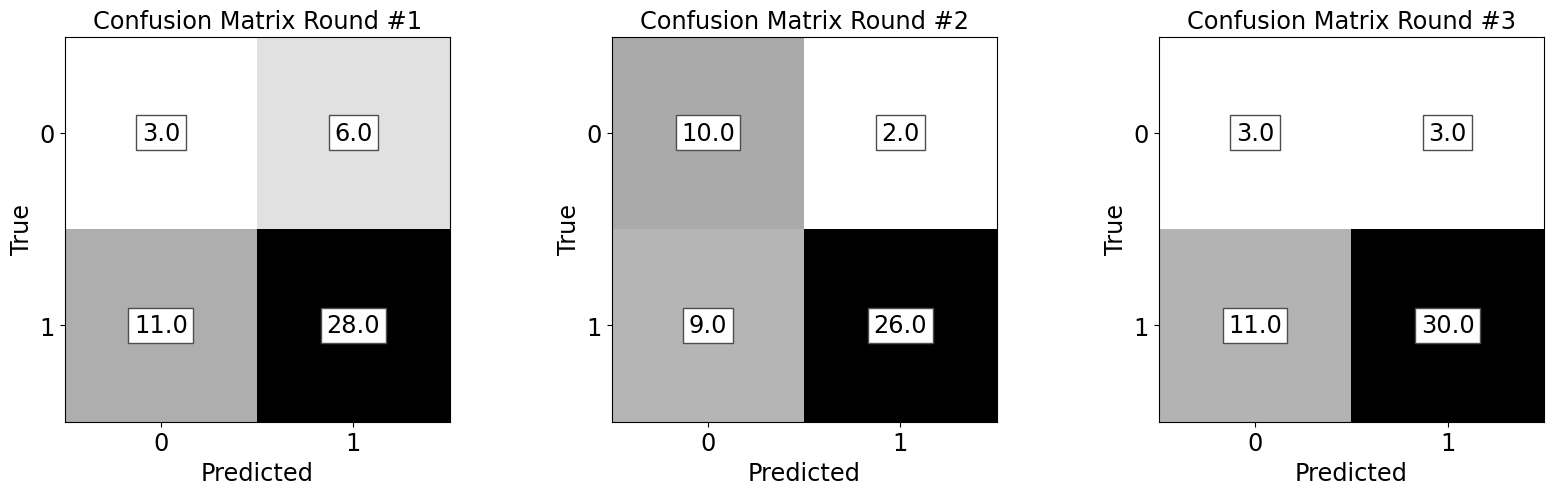

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


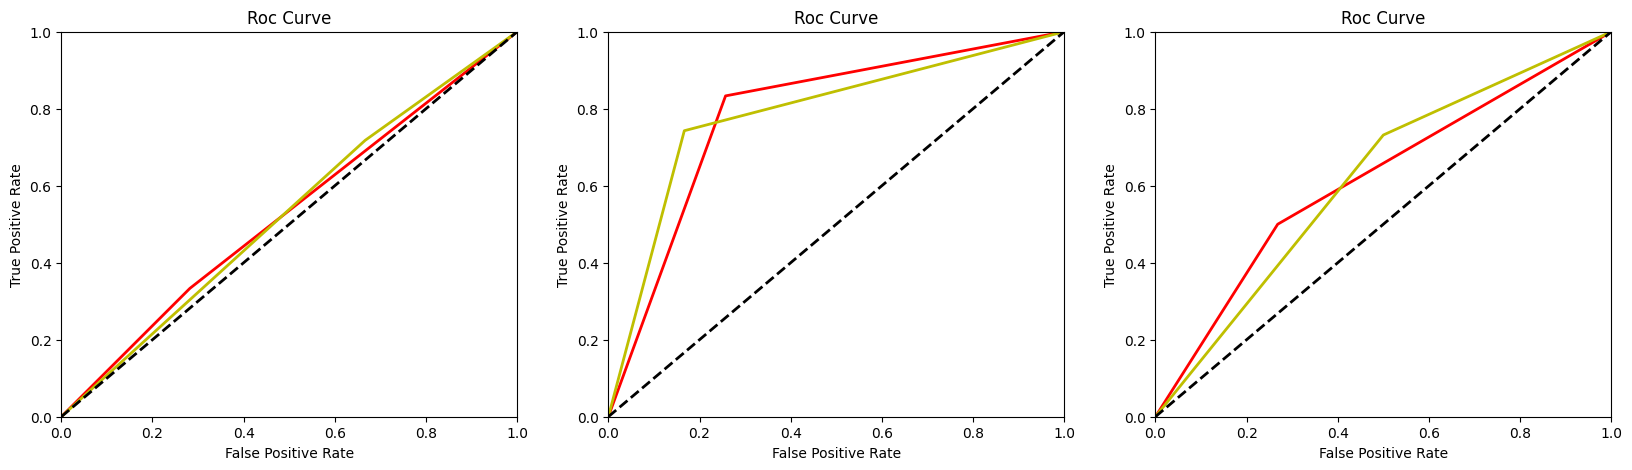

 77%|███████▋  | 20/26 [01:25<00:28,  4.81s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-080 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-080/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-080/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  192  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  121  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  121  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.8085020242914979 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 4  8]
 [16 33]]
cm.ravel() [ 4  8 16 33]
----- [0.50340136 0.33333333 0.67346939 0.2        0.80487805 0.5

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 6  6]
 [17 31]]
cm.ravel() [ 6  6 17 31]
----- [0.57291667 0.5        0.64583333 0.26086957 0.83783784 0.5493537
 0.34285714 0.72941176 0.53613445 0.57291667 0.5        0.16216216
 0.35416667 0.73913043 0.20689655] [[ 6  6]
 [17 31]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 5  7]
 [18 30]]
cm.ravel() [ 5  7 18 30]
----- [0.52083333 0.41666667 0.625      0.2173913  0.81081081 0.51410106
 0.28571429 0.70588235 0.49579832 0.52083333 0.58333333 0.18918919
 0.375      0.7826087  0.16666667] [[ 5  7]
 [18 30]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


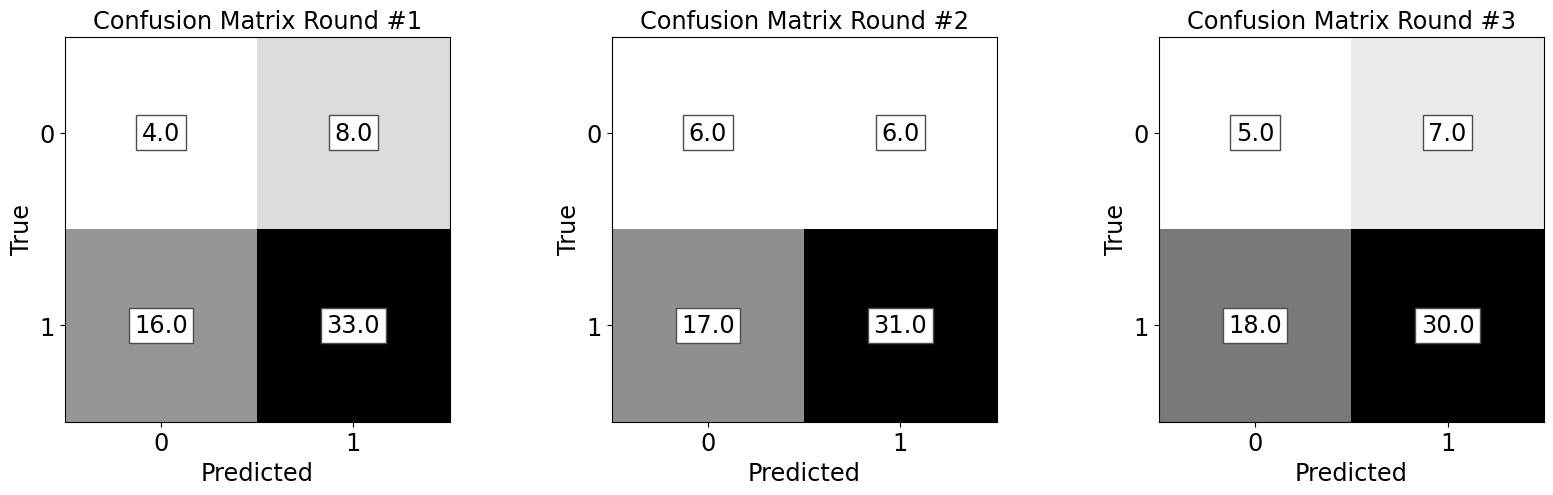

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


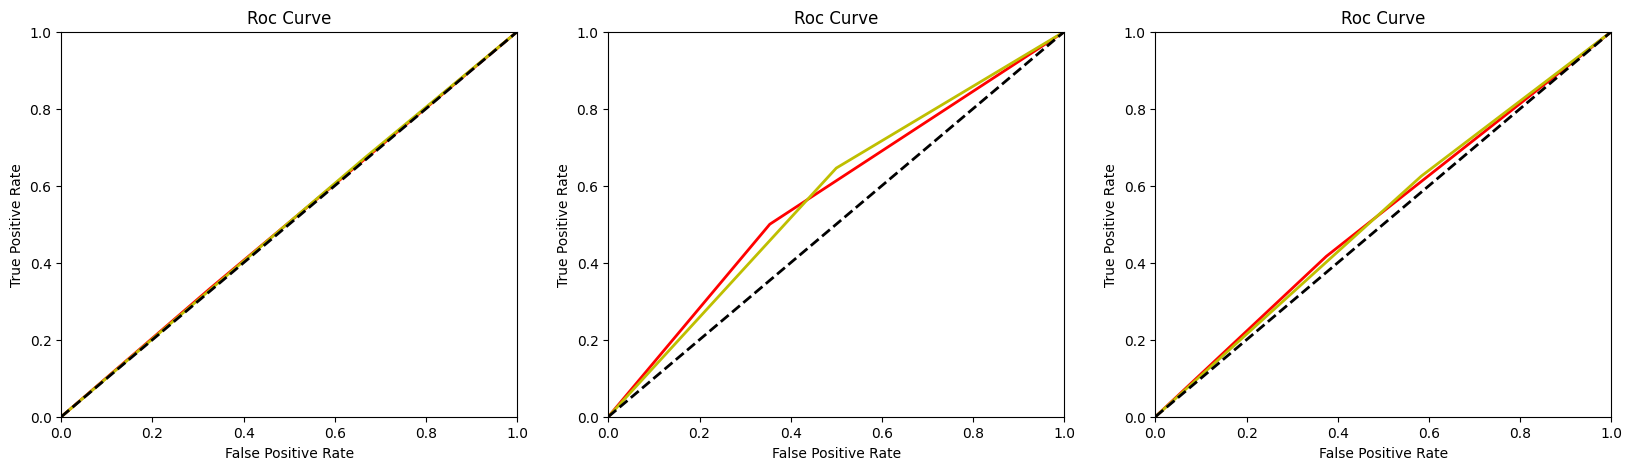

 81%|████████  | 21/26 [01:29<00:22,  4.48s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-082 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-082/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-082/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  91  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  144  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  91  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  150  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  92  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  154  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7147783251231528 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 1  5]
 [11 29]]
cm.ravel() [ 1  5 11 29]
----- [0.44583333 0.16666667 0.725      0.08333333 0.85294118 0.4681

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


cm [[ 4  5]
 [13 24]]
cm.ravel() [ 4  5 13 24]
----- [0.54654655 0.44444444 0.64864865 0.23529412 0.82758621 0.53144016
 0.30769231 0.72727273 0.51748252 0.54654655 0.55555556 0.17241379
 0.35135135 0.76470588 0.18181818] [[ 4  5]
 [13 24]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 4  6]
 [14 21]]
cm.ravel() [ 4  6 14 21]
----- [0.5        0.4        0.6        0.22222222 0.77777778 0.5
 0.28571429 0.67741935 0.48156682 0.5        0.6        0.22222222
 0.4        0.77777778 0.16666667] [[ 4  6]
 [14 21]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


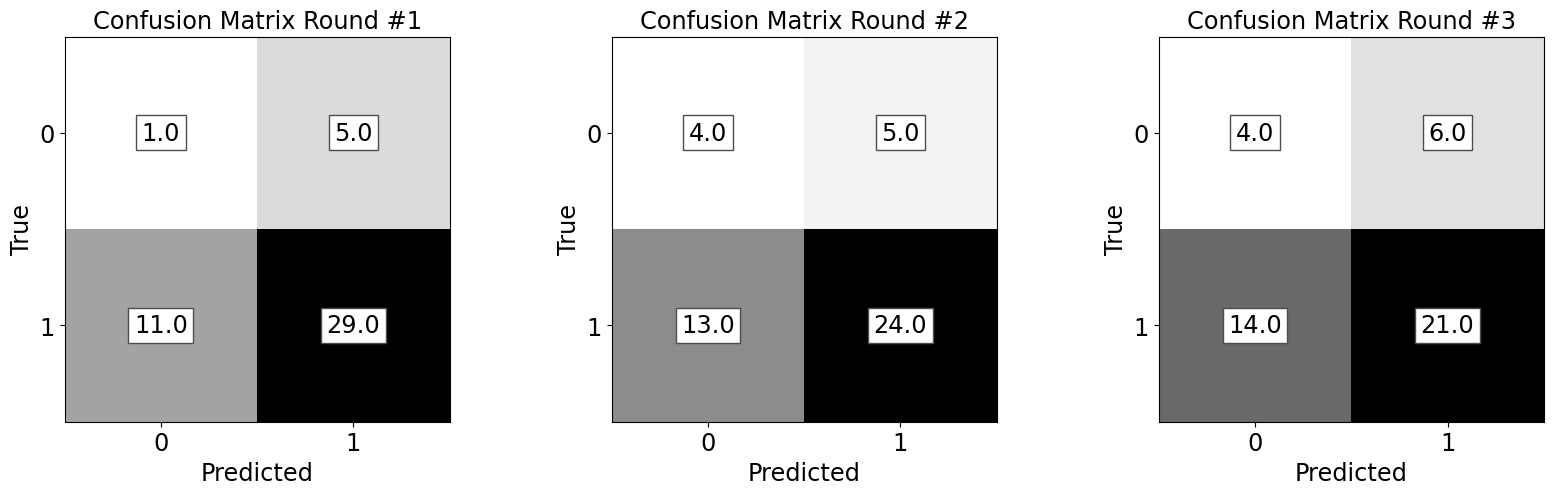

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


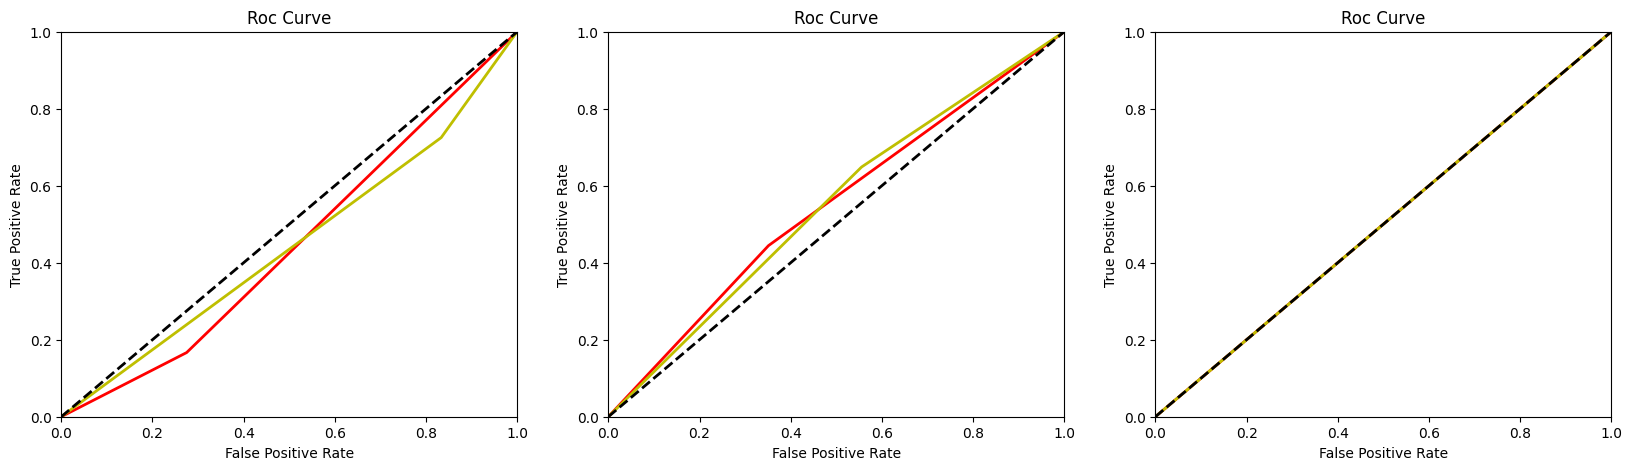

 88%|████████▊ | 23/26 [01:33<00:10,  3.43s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-083 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-083/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-083/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  137  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  212  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  137  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  222  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  138  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  222  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.702547065337763 KNeighborsClassifier(metric='manhattan', n_neighbors=3, weights='distance')
cm [[ 4  7]
 [23 35]]
cm.ravel() [ 4  7 23 35]
----- [0.48354232 0.36363636 0.60344828 0.1481

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.7389898989898989 KNeighborsClassifier(metric='manhattan', n_neighbors=3)
cm [[ 7  9]
 [15 38]]
cm.ravel() [ 7  9 15 38]
----- [0.57724057 0.4375     0.71698113 0.31818182 0.80851064 0.56334623
 0.36842105 0.76       0.56421053 0.57724057 0.5625     0.19148936
 0.28301887 0.68181818 0.22580645] [[ 7  9]
 [15 38]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[11  4]
 [33 20]]
cm.ravel() [11  4 33 20]
----- [0.55534591 0.73333333 0.37735849 0.25       0.83333333 0.54166667
 0.37288136 0.51948052 0.44618094 0.55534591 0.26666667 0.16666667
 0.62264151 0.75       0.22916667] [[11  4]
 [33 20]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'manhattan', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


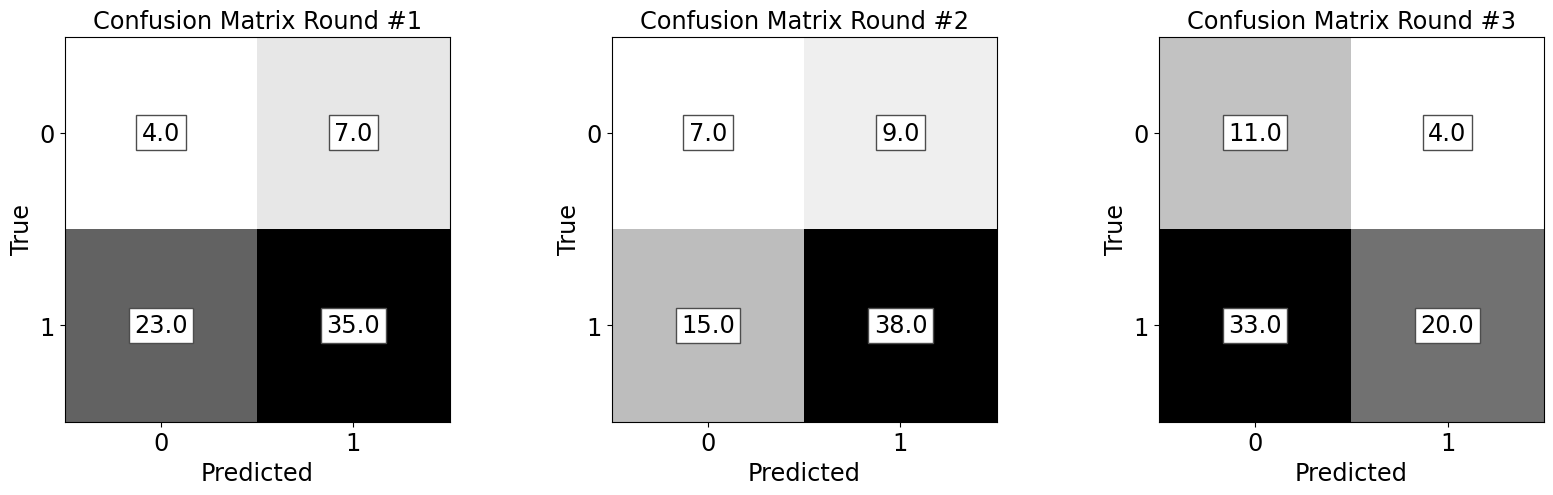

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


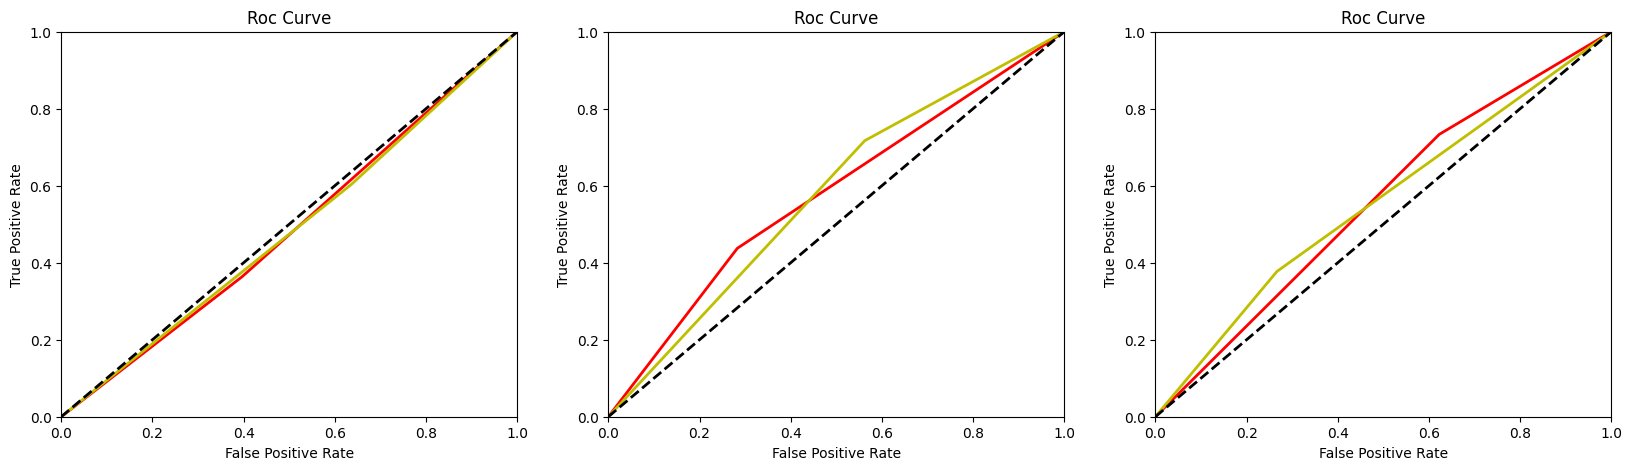

 92%|█████████▏| 24/26 [01:38<00:07,  3.91s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='manhattan', n_neighbors=3)
~~~~~~~~~~~~~~~~~ SB-112 ~~~~~~~~~~~~~~~~~~~~~~
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-112/K-NN/diagrams
/content/gdrive/MyDrive/ResearchProject/classification_results_2023/SB-112/K-NN/diagrams/sklearn_models_
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  194  ~~~~~~~~~~
~~~~~~~~~~ Number of instances before balancing:  120  ~~~~~~~~~~
~~~~~~~~~~ Number of instances after balancing:  188  ~~~~~~~~~~
~~~~~~~~~~ K-NN ~~~~~~~~~~~~~~~
-----------kfold--------------- 0 ------------
---K-NN--- 0.7002699055330635 KNeighborsClassifier(metric='manhattan', n_neighbors=3, weights='distance')
cm [[ 6  7]
 [16 31]]
cm.ravel() [ 6  7 16 31]
----- [0.56055646 0.46153846 0.65957447 0.272

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


---K-NN--- 0.81889338731444 KNeighborsClassifier(metric='euclidean', weights='distance')
cm [[ 3 10]
 [13 34]]
cm.ravel() [ 3 10 13 34]
----- [0.47708674 0.23076923 0.72340426 0.1875     0.77272727 0.48011364
 0.20689655 0.74725275 0.47707465 0.47708674 0.76923077 0.22727273
 0.27659574 0.8125     0.11538462] [[ 3 10]
 [13 34]]
* 1-----------kfold--------------- 2 ------------


/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:416: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_xticklabels([''] + ['0', '1'], fontsize='xx-large')
/content/gdrive/MyDrive/ResearchProject/classification/Base_Model/Classificationv3.py:417: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[i].set_yticklabels([''] + ['0', '1'], fontsize='xx-large')


cm [[ 6  4]
 [22 28]]
cm.ravel() [ 6  4 22 28]
----- [0.58       0.6        0.56       0.21428571 0.875      0.54464286
 0.31578947 0.68292683 0.49935815 0.58       0.4        0.125
 0.44       0.78571429 0.1875    ] [[ 6  4]
 [22 28]]
* 2*
{'algorithm': 'auto', 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
------run_cv runs successfully------------
++++++++++++save_confusion_matrix++++++++++++


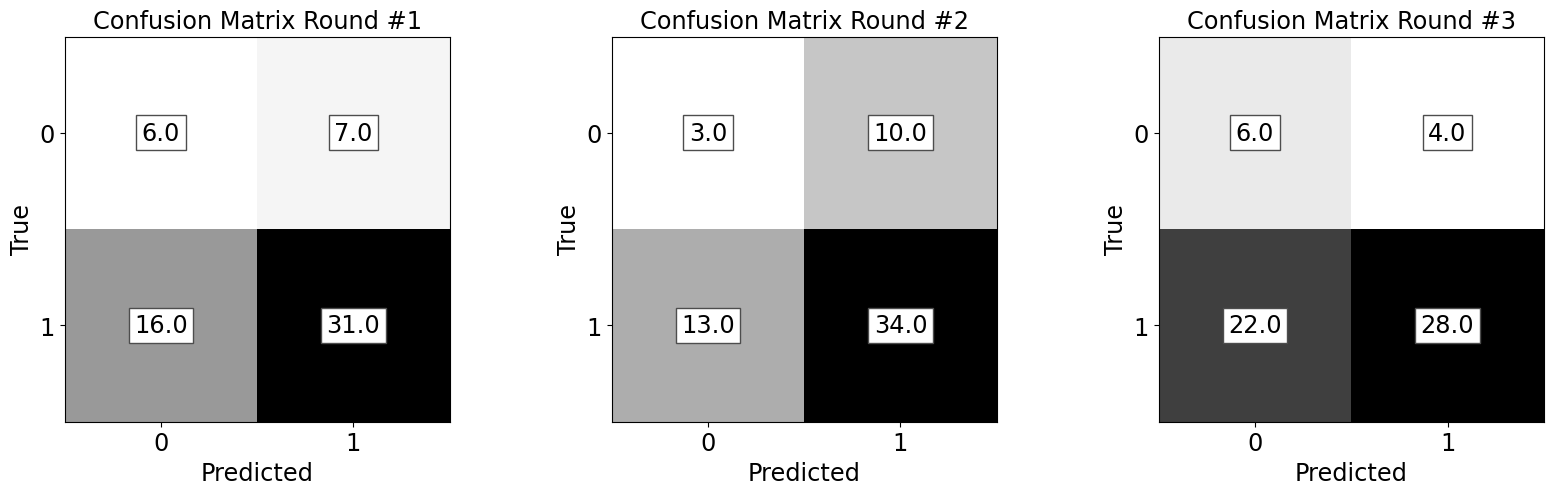

++++++++++++save_confusion_matrix end++++++++++++
(((((((((((((((((((((( draw droc ))))))))))))))))))))))))))))))


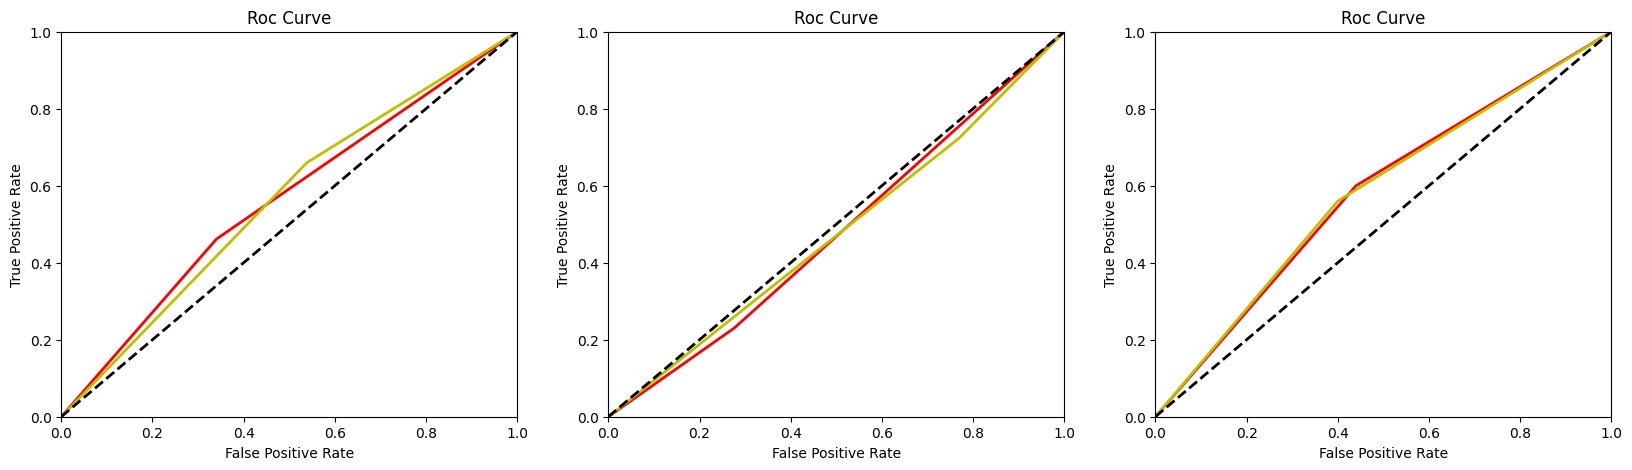

100%|██████████| 26/26 [01:42<00:00,  3.95s/it]

(((((((( draw droc end ))))))))
KNeighborsClassifier(metric='euclidean', weights='distance')


In [20]:
KNNRunner('K-NN')